## 🎯 Análisis Predicción y Clasificación en la Industria Azucarera

### **Parte 1: Regresión Lineal**

📅 Fecha: 2025

👤 Equipo:

- Valentina Giraldo Gaviria
- Diana Marcela Silva
- Marcela Fajardo Bermúdez
- Hector Hernan Betancourt López

### **Entendimiento del negocio**

 El Ingenio La Providencia cuenta con un conjunto de datos históricos que recoge información relevante sobre la producción de caña de azúcar. Este taller tiene como objetivo que ustedes, como estudiantes, apliquen los conocimientos adquiridos en el curso para desarrollar modelos que permitan desarrollar la siguiente tarea:

1.  Regresión (HISTORICO_SUERTES.xlsx): Predecir dos variables clave:


- `TCH` (Toneladas de Caña por Hectárea)
- `%Sac.Caña` (Porcentaje de sacarosa en caña)

### **0. Importación Liberarias**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
import scipy.sparse as sp
import statsmodels.api as sm
import unicodedata

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.preprocessing import FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn import set_config
from sklearn.model_selection import ShuffleSplit, cross_validate
from sklearn.linear_model import LassoCV
from sklearn.linear_model import RidgeCV

from statsmodels.stats.diagnostic import het_breuschpagan, het_white
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from statsmodels.stats.outliers_influence import variance_inflation_factor

from scipy.stats import shapiro

from unidecode import unidecode
from pandas.api.types import is_categorical_dtype
from IPython.display import display


### **1. Carga de datos y vista rápida**

In [2]:
# Carga de datos
df = pd.read_excel(r"C:\Users\1116282909\OneDrive - Universidad Icesi\Escritorio\Maestría en Ciencia de Datos\Analisis Cuantitativo\Taller final/HISTORICO_SUERTES.xlsx")

In [3]:
# Vista rápida
df.head()

,Período,Hacienda,Nombre,Zona,Tenencia,Suerte,Suelo,Area Neta,Dist Km,Variedad,...,Humedad Rel Media Ciclo,Oscilacion Temp Med 0-3,Oscilacion Temp Ciclo,Sum Oscilacion Temp Ciclo,Radicion Solar 0-3,Radiacion Solar Ciclo,Precipitacion 0_3,Precipitacion Ciclo,Evaporacion 0-3,Evaporacion Ciclo
0,201701,80493,LA CONCHA,IP02,51.0,002A,CANTARINA,6.00,4.3,CC85-92,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,201701,81284,UKRANIA INCAUCA,IP05,81.0,039B,NaN,1.45,NaN,CC85-92,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,201701,80203,EL AMPARO SAA,IP05,31.0,007,CORINTIAS,8.24,23.0,CC01-1228,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,201701,81380,SAN JUDAS INCAUCA,IP05,82.0,013A,NaN,1.05,66.5,CC01-1940,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,201701,80298,JAVA,IP06,31.0,025A,GALPON,4.53,17.0,RB73-2223,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
# Tamaño de la base de datos
df.shape

(21027, 85)

**Interpretación:**

La información anterior indica que la data de historicos tiene un total de 21.027 registros con 85 columnas

### **2. Nulos: imputación y resumen**

- Se imputan dos campos con reglas de negocio:
- `'%Infest.Diatrea'` → 0 cuando nulo
- `'Producto'` → 'Sin producto' cuando nulo
- Se construye un **resumen de nulos** absoluto y relativo.
- Se eliminan columnas con **> 60%** de nulos.

In [5]:
# Imputación por criterio de negocio

df['%Infest.Diatrea'] = df['%Infest.Diatrea'].fillna(0)
df['Producto'] = df['Producto'].fillna('Sin producto')

In [6]:
# Resumen de nulos (antes de eliminar columnas)

nulos_abs = df.isna().sum()
nulos_pct = df.isna().mean() * 100

resumen_nulos = (
    pd.DataFrame({"n_nulos": nulos_abs, "pct_nulos": nulos_pct})
      .sort_values("pct_nulos", ascending=False)
)


# mostrar con formato
print(resumen_nulos.to_string(formatters={"pct_nulos": "{:.2f}%".format}))

                           n_nulos pct_nulos
Sum Oscilacion Temp Ciclo    21027   100.00%
Fert.Nitrogen.               21027   100.00%
Urea 46%                     20304    96.56%
NITRAX-S                     20279    96.44%
MEZ                          20056    95.38%
MicroZinc                    19878    94.54%
Boro Granul.                 19742    93.89%
Sul.Amonio                   19670    93.55%
NITO_XTEND                   17348    82.50%
Vinaza                       16929    80.51%
Humedad Rel Media Ciclo      16497    78.46%
Temp. Media 0-3              16497    78.46%
Oscilacion Temp Med 0-3      16497    78.46%
Temp. Media Ciclo            16497    78.46%
Temp Max Ciclo               16497    78.46%
Humedad Rel Media 0-3        16497    78.46%
Radiacion Solar Ciclo        16497    78.46%
Evaporacion 0-3              16497    78.46%
Precipitacion Ciclo          16497    78.46%
Evaporacion Ciclo            16497    78.46%
Temp Min Ciclo               16497    78.46%
Oscilacion

In [7]:
# Seleccionar columnas con más de 60% nulos
cols_a_eliminar = nulos_pct[nulos_pct > 60].index

# Eliminar esas columnas
df = df.drop(cols_a_eliminar, axis=1)

print("Columnas eliminadas:", list(cols_a_eliminar))

Columnas eliminadas: ['D.S.', 'Fert.Nitrogen.', 'Urea 46%', 'MEZ', 'Boro Granul.', 'MicroZinc', 'NITO_XTEND', 'Sul.Amonio', 'NITRAX-S', 'Vinaza', 'Codigo Estacion', 'Temp. Media 0-3', 'Temp. Media Ciclo', 'Temp Max Ciclo', 'Temp Min Ciclo', 'Humedad Rel Media 0-3 ', 'Humedad Rel Media Ciclo', 'Oscilacion Temp Med 0-3', 'Oscilacion Temp Ciclo', 'Sum Oscilacion Temp Ciclo', 'Radicion Solar 0-3', 'Radiacion Solar Ciclo', 'Precipitacion 0_3', 'Precipitacion Ciclo', 'Evaporacion 0-3', 'Evaporacion Ciclo']


In [8]:
# Resumen de nulos (después)

nulos_abs_1 = df.isna().sum()
nulos_pct_1 = df.isna().mean() * 100

resumen_nulos = (
    pd.DataFrame({"n_nulos": nulos_abs_1, "pct_nulos": nulos_pct_1})
      .sort_values("pct_nulos", ascending=False)
)


# mostrar con formato
print(resumen_nulos.to_string(formatters={"pct_nulos": "{:.2f}%".format}))

                        n_nulos pct_nulos
Num.Riegos                12589    59.87%
Ult.Riego                 12557    59.72%
Edad.Precosecha           12108    57.58%
Fec.Madur.                 9775    46.49%
Semanas mad.               9775    46.49%
Suelo                      3758    17.87%
Vejez                      2445    11.63%
%AR Jugo                   2124    10.10%
%Sac.Muestreadora          1858     8.84%
Fosfato Jugo               1858     8.84%
%Fibra Caña                1858     8.84%
%ME Min                    1722     8.19%
%ME Tot                    1720     8.18%
%ME Veg                    1720     8.18%
Sac.Caña Precosecha        1098     5.22%
%ATR                        522     2.48%
KATRHM                      522     2.48%
%Sac.Caña                   449     2.14%
Pureza                      269     1.28%
Rdto                        267     1.27%
Brix                        267     1.27%
TAH                         241     1.15%
Ton.Azucar                  241   

### **3. Estandarización ligera de texto (Producto)**

- Normaliza acentos y espacios para evitar **cardinalidad artificial**.

In [9]:
df["Producto"].unique()

array(['BONUS 250 EC REGULADOR FISIOLÓGICO', 'Sin producto', 'AGROFOSK-M',
       'FUSILADE 2000 BL', 'OTROS MADURANTES',
       'PRODUCTO ENSAYO EN LITROS', 'ROUND-UP MONSANTO 747 GRANULADO',
       'FERTILIZANTE LIQUIDO RENDIMIENTO', 'GREEN LIFE',
       'MADURANTE REGULADOR TRONNUSPAC 250 EC', 'COADYUVANTE  DOUCE',
       'MADURANTE BIO SAFE ORGANIC', 'AMINA 2-4-D', 'baykal',
       'HERBICIDA CLICK 40 SC', 'GLIFOLAQ',
       'BONUS 250 EC REGULADOR FISIOLOGICO', 'TRANSLOK',
       'FERTILIZANTE ORGÁNICO PATER-M'], dtype=object)

In [10]:
df["Producto"] = (
    df["Producto"].astype("string")
                  .map(lambda x: unidecode(x) if pd.notna(x) else x)
                  .str.strip()
                  .str.replace(r"\s+", " ", regex=True))

In [11]:
df["Zona"].unique()

array(['IP02', 'IP05', 'IP06', 'IP03', 'IP01', 'ip05', 'IC07'],
      dtype=object)

In [12]:
# Estandarizar: trim + colapsar espacios + MAYÚSCULAS
df['Zona'] = (df['Zona'].astype('string')
                        .str.strip()
                        .str.replace(r'\s+', ' ', regex=True)
                        .str.upper())

### **4. Dominancia: identificación de columnas poco informativas**

Construimos un **resumen de dominancia** por columna:
- `%missing`: porcentaje de faltantes
- `n_unique`: cardinalidad
- `top_%`: proporción de la categoría/valor más frecuente
- `entropia_norm`: 0 (muy dominante) → 1 (distribución uniforme)

Marcamos:
- `constante`: `n_unique <= 1`
- `dominante`: `top_% >= thr_dom` (por defecto, 70%)

In [13]:
# Parámetros de dominancia

thr_dom = 0.70      # umbral de dominancia
cols    = df.columns    

rows = []
for c in cols:
    s = df[c]
    n_total   = len(s)
    n_valid   = s.notna().sum()
    n_missing = n_total - n_valid
    nunique   = s.nunique(dropna=True)

    vc = s.value_counts(dropna=True)
    top_val  = vc.index[0] if len(vc) else np.nan
    top_freq = int(vc.iloc[0]) if len(vc) else 0
    top_pct  = (top_freq / n_valid) if n_valid > 0 else np.nan

    # Entropía normalizada (0 = muy dominante, 1 = uniforme)
    p = (vc / n_valid).values if (n_valid > 0 and len(vc) > 0) else np.array([])
    ent = -(p * np.log(p)).sum() if p.size else 0.0
    ent_max = np.log(len(vc)) if len(vc) > 1 else 0.0
    ent_norm = float(ent / ent_max) if ent_max > 0 else 0.0

    rows.append({
        "columna": c,
        "dtype": str(s.dtype),
        "n": n_total,
        "n_valid": n_valid,
        "n_missing": n_missing,
        "%missing": round(n_missing / n_total * 100, 2),
        "n_unique": int(nunique),
        "top": top_val,
        "top_freq": top_freq,
        "top_%": round(top_pct * 100, 2) if pd.notna(top_pct) else np.nan,
        "entropia_norm": round(ent_norm, 3),
        "constante": nunique <= 1,
        "dominante": (nunique > 1) and pd.notna(top_pct) and (top_pct >= thr_dom),
        "binaria": nunique == 2
    })

resumen_dominancia = (
    pd.DataFrame(rows)
      .sort_values(["constante", "dominante", "top_%", "n_unique"],
                   ascending=[False, False, False, True])
      .reset_index(drop=True)
)

resumen_dominancia

,columna,dtype,n,n_valid,n_missing,%missing,n_unique,top,top_freq,top_%,entropia_norm,constante,dominante,binaria
0,Destino 1=Semilla,int64,21027,21027,0,0.00,2,0,20733,98.60,0.106,False,True,True
1,Cod. T.Cultivo,float64,21027,21025,2,0.01,2,1.0,20266,96.39,0.224,False,True,True
2,Cultivo,object,21027,21025,2,0.01,2,Normal,20266,96.39,0.224,False,True,True
3,Cosechó,object,21027,21027,0,0.00,14,AI08,19043,90.56,0.153,False,True,False
4,T.Corte,object,21027,21027,0,0.00,4,MECANIZADO,17121,81.42,0.401,False,True,False
5,Tipo Quema,object,21027,21027,0,0.00,5,VERDE,16204,77.06,0.494,False,True,False
6,%Infest.Diatrea,float64,21027,21027,0,0.00,5206,0.0,15428,73.37,0.333,False,True,False
7,DDUlt.Riego,int64,21027,21027,0,0.00,427,0,12571,59.79,0.482,False,False,False
8,M3 Riego,float64,21027,21027,0,0.00,6820,0.0,12557,59.72,0.468,False,False,False
9,Sac.Caña Precosecha,float64,21027,19929,1098,5.22,7892,0.0,10770,54.04,0.534,False,False,False


**Nota**: Reconocemos que al calcular estas dominancias podría generarse fuga de datos (data leakage). No obstante, resulta necesario aplicar un tratamiento general a la base y depurar algunas variables antes de realizar la partición en conjuntos de entrenamiento y prueba (Train/Test split).

**Selección de columnas dominantes a eliminar**

Se excluyen manualmente algunas columnas que, aunque dominantes, son **relevantes para el negocio/modelado**.


In [14]:
cols_dominantes = resumen_dominancia.loc[resumen_dominancia["dominante"], "columna"].tolist()

cols_no_quitar = ["Tipo Quema", "%Infest.Diatrea", "T.Corte","Cod. T.Cultivo"] 
cols_dominantes = [col for col in cols_dominantes if col not in cols_no_quitar]

cols_dominantes

['Destino 1=Semilla', 'Cultivo', 'Cosechó']

In [15]:
# Eliminación

df = df.drop(columns=cols_dominantes, errors="ignore")

In [16]:
# inspección rápida
df

,Período,Hacienda,Nombre,Zona,Tenencia,Suerte,Suelo,Area Neta,Dist Km,Variedad,...,M3 Riego,DDUlt.Riego,Lluvias (2 Meses Ant.),Lluvias Ciclo,Lluvias 0 -3,Lluvias tres a seis,Lluvias seis a nueve,Luvias 9 -FC,%Infest.Diatrea,Fosfato Jugo
0,201701,80493,LA CONCHA,IP02,51.0,002A,CANTARINA,6.00,4.3,CC85-92,...,0.00,0,258.0,1038.0,0.0,454.0,102.0,482.0,0.0000,178.0
1,201701,81284,UKRANIA INCAUCA,IP05,81.0,039B,NaN,1.45,NaN,CC85-92,...,0.00,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0000,382.0
2,201701,80203,EL AMPARO SAA,IP05,31.0,007,CORINTIAS,8.24,23.0,CC01-1228,...,48513.60,107,246.0,1002.0,106.0,326.0,113.0,457.0,0.0000,226.0
3,201701,81380,SAN JUDAS INCAUCA,IP05,82.0,013A,NaN,1.05,66.5,CC01-1940,...,0.00,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0000,278.0
4,201701,80298,JAVA,IP06,31.0,025A,GALPON,4.53,17.0,RB73-2223,...,0.00,0,138.0,991.0,264.0,255.0,188.0,284.0,0.0000,244.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21022,202407,80102,LA PAZ,IP01,11.0,051B,LA PAZ,3.00,1.8,CC05-430,...,16605.96,27,200.0,1123.0,137.0,225.0,201.0,560.0,0.0000,NaN
21023,202407,80102,LA PAZ,IP01,11.0,054C,LA PAZ,1.22,1.8,CC05-430,...,6435.60,25,200.0,1139.0,138.0,231.0,210.0,560.0,0.0000,NaN
21024,202407,80102,LA PAZ,IP01,11.0,054E,LA PAZ,1.85,1.8,CC05-430,...,9564.96,25,200.0,1139.0,138.0,231.0,210.0,560.0,0.0000,NaN
21025,202407,80104,SAMARIA,IP02,11.0,165,PALMIRA,31.42,3.5,CC05-430,...,289740.00,40,212.0,905.0,136.0,211.0,164.0,394.0,1.6367,NaN


### **5. Feature engineering ligero**

- `M3_Riego_ha` = `M3 Riego` / `Area Neta` (razón por ha).
- Eliminación de columnas de alta cardinalidad o de fecha/ID que no aportan al modelo lineal.

In [17]:
# Ratio de riego por ha (convierte a numérico para evitar errores)

df["M3_Riego_ha"] = (
    pd.to_numeric(df["M3 Riego"], errors="coerce") /
    pd.to_numeric(df["Area Neta"], errors="coerce")
)

In [18]:
# Columnas de cardinalidad/fechas/IDs a remover (criterio de parsimonia)

cols_a_eliminar_2 = ["Período","Hacienda","Nombre", "Suerte","Suelo","Cod.Estado","F.Siembra", "F.Ult.Corte","Cerca de","Cosechó","Ult.Riego","Fec.Madur.","Ult_Riego","Lluvias (2 Meses Ant.)", "Lluvias 0 -3", "Lluvias tres a seis", "Lluvias seis a nueve", "Luvias 9 -FC", "Num.Riegos", "M3 Riego"]
df = df.drop(columns=cols_a_eliminar_2, errors="ignore")

# Se eliminan variables por alta cardinalidas, repetidas o que tienen otra variable calculada a partir de estas.

**Agrupación de categorías raras** (Top-8) para `Variedad` y `Producto`:

- Mantiene interpretabilidad y evita alta dimensionalidad en OHE.

In [19]:
# Top-8 por frecuencia

top_v = df["Variedad"].value_counts(dropna=False).head(8).index
top_p = df["Producto"].value_counts(dropna=False).head(8).index

# Reemplaza fuera del Top-8 por "OTRAS" y deja como categórica (útil para OHE)
df["Variedad"] = pd.Categorical(
    np.where(df["Variedad"].isin(top_v), df["Variedad"], "OTRAS"),
    categories=list(top_v) + ["OTRAS"]
)

df["Producto"] = pd.Categorical(
    np.where(df["Producto"].isin(top_p), df["Producto"], "OTRAS"),
    categories=list(top_p) + ["OTRAS"]
)

In [20]:
df["Tipo Quema"].value_counts()

Tipo Quema
VERDE           16204
Q.ACCIDENTAL     2470
Q.PROGRAMADA     1536
NO DEF.           523
SEMILLA           294
Name: count, dtype: int64

Nota: El dato "Semilla" no tiene sentido como tipo de quema. Por lo que decidimos omitirla del dataframe en estudio

In [21]:
df = df[df["Tipo Quema"] != "SEMILLA"]

In [22]:
cat_cols = df.select_dtypes(include=["object","string","category","bool"]).columns

In [23]:
counts = (
    df[cat_cols]
      .apply(lambda s: s.astype("string").str.strip().str.replace(r"\s+"," ", regex=True).str.upper())
      .melt(var_name="col", value_name="categoria")
      .groupby(["col","categoria"], dropna=False)
      .size()
      .reset_index(name="conteo")
)
# categorías con 1 registro
singletons = counts[counts["conteo"] == 1]

singletons

## Tras la selección de variables, se detectaron categorías con una única observación. Para evitar que afecten el Train/Test split (dificulten la estratificación o introduzcan ruido), se eliminaron dichas observaciones del DataFrame de análisis.

,col,categoria,conteo
25,Zona,IC07,1


In [24]:
df = df[df["Zona"] != "IC07"]

In [25]:
# Descripción estadística de variables númericas

df.describe()

,Tenencia,Area Neta,Dist Km,Cod.Estado #,Edad Ult Cos,Cod. T.Cultivo,Dosis Madurante,Semanas mad.,TonUltCorte,TCH,...,%ME Veg,%ME Tot,Brix,Pureza,Vejez,DDUlt.Riego,Lluvias Ciclo,%Infest.Diatrea,Fosfato Jugo,M3_Riego_ha
count,20731.000000,20732.000000,20727.000000,20732.000000,20732.000000,20730.000000,20636.000000,11238.000000,20732.000000,20732.000000,...,19305.000000,19305.000000,20577.000000,20575.000000,18484.000000,20732.000000,20732.000000,20732.000000,18987.000000,2.073200e+04
mean,46.907771,8.703158,25.509595,4.307640,13.064856,1.033960,0.543009,9.589695,1152.060318,130.072962,...,7.761516,8.600853,13.246645,78.493182,12.307118,45.862001,523.506232,1.028203,335.680333,4.230885e+03
std,21.281305,7.060322,18.255255,4.120044,1.931559,0.181132,0.539709,5.576041,1020.185969,32.492034,...,3.108536,2.482623,4.072505,23.471837,21.016445,76.797334,553.776876,2.238052,1612.527060,5.066124e+04
min,11.000000,0.004000,1.100000,0.000000,5.550000,1.000000,0.000000,-2.000000,0.420000,3.055379,...,0.000000,0.200000,0.000000,0.000000,0.017000,0.000000,0.000000,0.000000,0.000000,0.000000e+00
25%,31.000000,3.380000,12.000000,1.000000,11.960000,1.000000,0.000000,6.571428,407.487500,109.246158,...,6.786800,7.432000,13.502000,83.608650,2.110000,0.000000,0.000000,0.000000,234.786850,0.000000e+00
50%,51.000000,7.080000,22.000000,3.000000,12.650000,1.000000,0.600000,8.571428,880.525000,129.815621,...,8.086000,8.666000,14.321600,85.551200,2.739000,0.000000,436.000000,0.000000,290.000000,0.000000e+00
75%,51.000000,12.130000,32.700000,6.000000,13.860000,1.000000,1.000000,11.142857,1604.709750,150.608500,...,9.218000,10.025000,15.051100,86.980900,10.792000,72.000000,922.000000,1.035625,360.000000,4.799341e+03
max,91.000000,65.000000,155.000000,31.000000,78.190000,2.000000,5.000000,96.285714,13586.140000,301.608000,...,240.084200,67.514000,19.323000,147.497100,205.650000,853.000000,3917.000000,29.838700,143728.067500,5.020200e+06


In [26]:
# Descripción estadística de variables categóricas

df[cat_cols].describe(include=["object","category","bool"])

,Variedad,Producto,Tipo Quema,T.Corte
count,20732,20732,20732,20732
unique,9,9,4,3
top,CC01-1940,BONUS 250 EC REGULADOR FISIOLOGICO,VERDE,MECANIZADO
freq,9091,10367,16203,17086


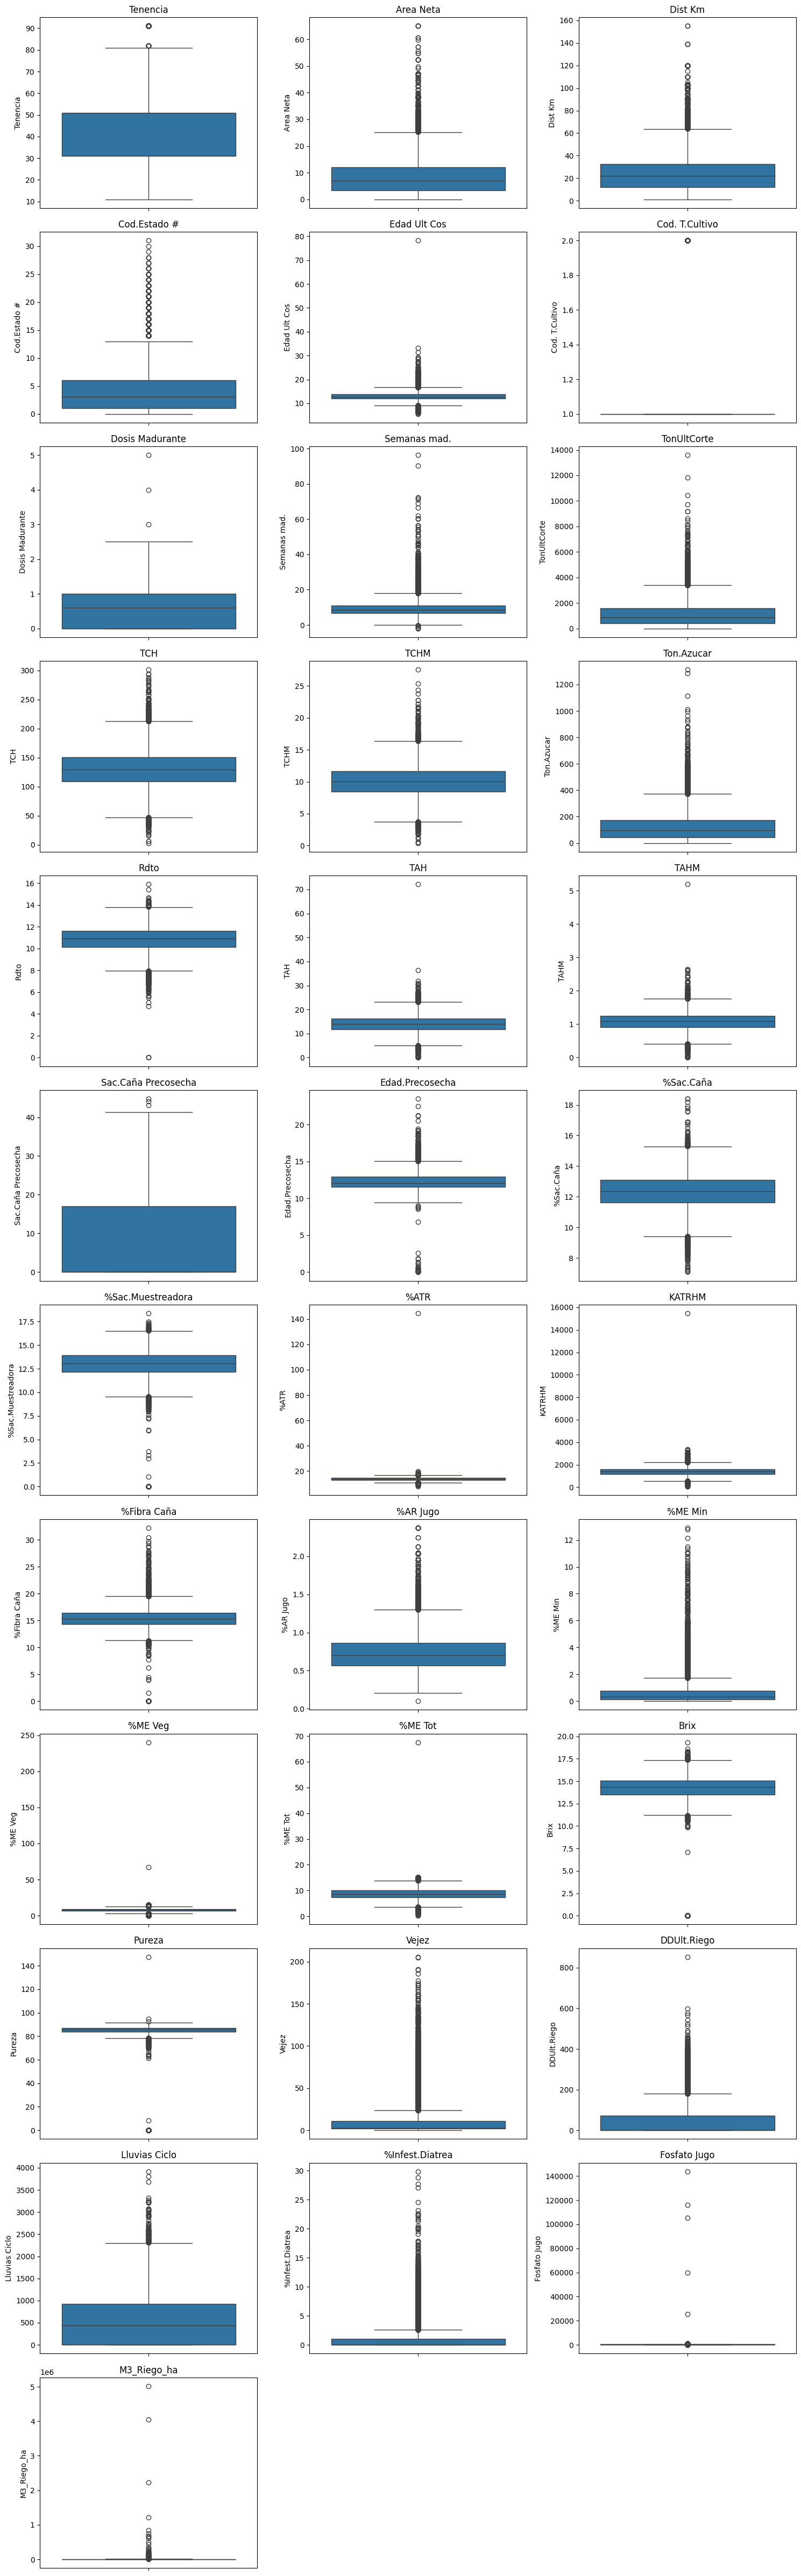

In [27]:
# Seleccionar numéricas
num_cols = df.select_dtypes(include=["int64", "float64"]).columns

# Definir tamaño de grid
n = len(num_cols)
cols = 3   # número de columnas en la grilla
rows = math.ceil(n / cols)

plt.figure(figsize=(15, rows*4))

for i, col in enumerate(num_cols, 1):
    plt.subplot(rows, cols, i)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

### **7. Definición de objetivos y partición Train/Test**

In [28]:
# Objetivos

y_cols = ["TCH", "%Sac.Caña"]

# Elimina filas con NaN en las Y

df = df.dropna(subset=y_cols).reset_index(drop=True)

In [29]:
# Matrices

X = df.drop(columns=["TCH", "%Sac.Caña"]).copy()
Y = df[["TCH", "%Sac.Caña"]].copy()

In [30]:
# Split (hold-out)

X_tr, X_te, Y_tr, Y_te = train_test_split(X, Y, test_size=0.3, random_state=42)


Si bien reconocemos que en etapas previas del tratamiento puede producirse una mínima fuga de datos (data leakage), la partición en conjuntos de entrenamiento y prueba (Train/Test) se realiza antes de aplicar los cálculos de imputación y la eliminación de atípicos, con el fin de reducir en la mayor medida posible dicho riesgo.

### **8. Preprocesamiento y outliers (winsorización IQR)**

**Pipeline numérico**:
- `IQRWinsorizer`: recorta extremos a [Q1−k·IQR, Q3+k·IQR] por variable
- `SimpleImputer(strategy="median")`: imputación robusta
- `StandardScaler`: escalado a media 0, var 1

**Pipeline categórico**:
- `SimpleImputer(most_frequent)`
- `OneHotEncoder(drop="first", handle_unknown="ignore")`

In [31]:
# Transformer: winsorización por IQR

class IQRWinsorizer(BaseEstimator, TransformerMixin):
    """Recorta valores extremos usando IQR por columna.
    Parámetros:
      q_low, q_high: cuantiles para Q1/Q3
      k: multiplicador del IQR
    Manejo especial: si IQR=0 o NaN, no recorta esa columna.
    """
    def __init__(self, q_low=0.25, q_high=0.75, k=1.5):
        self.q_low = q_low
        self.q_high = q_high
        self.k = k

    def fit(self, X, y=None):
        Xdf = X if isinstance(X, pd.DataFrame) else pd.DataFrame(X)
        q1 = Xdf.quantile(self.q_low)
        q3 = Xdf.quantile(self.q_high)
        iqr = q3 - q1

        low  = q1 - self.k * iqr
        high = q3 + self.k * iqr

        mask_bad = iqr.isna() | (iqr == 0)
        low[mask_bad]  = -np.inf
        high[mask_bad] =  np.inf

        self.low_  = low.to_numpy()
        self.high_ = high.to_numpy()
        self.feature_names_in_ = getattr(Xdf, "columns", np.arange(Xdf.shape[1]))
        return self

    def transform(self, X):
        Xarr = X.to_numpy() if isinstance(X, pd.DataFrame) else np.asarray(X)
        return np.clip(Xarr, self.low_, self.high_)

    def get_feature_names_out(self, input_features=None):
        feats = input_features if input_features is not None else self.feature_names_in_
        return np.asarray(feats, dtype=object)

# Columnas por tipo usando SOLO TRAIN

num_cols = X_tr.select_dtypes(include=[np.number, "Int64", "Float64"]).columns
cat_cols = X_tr.select_dtypes(include=["object","string","category","bool"]).columns

# Pipelines

num_pipe = Pipeline([
    ("winsor", IQRWinsorizer(k=1.5)),                # IQR winsor
    ("imp", SimpleImputer(strategy="median")),       # Imputación por la mediana
    ("sc", StandardScaler()),                        # Escala
])
cat_pipe = Pipeline([
    ("imp", SimpleImputer(strategy="most_frequent")),                     # Imputación por la moda
    ("ohe", OneHotEncoder(drop="first", handle_unknown="ignore")),        # OneHotEncoder
])

preprocesamiento = ColumnTransformer(
    transformers=[
        ("num", num_pipe, num_cols),
        ("cat", cat_pipe, cat_cols),
    ],
    remainder="drop",
    verbose_feature_names_out=False      # Al pedir nombres de salida, evita prefijos tipo "num__" o "cat__".
)
preprocesamiento

,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False
,force_int_remainder_cols,'deprecated'
,q_low,0.25
,q_high,0.75
,k,1.5


#### **8.1. Transformación de TRAIN y visualización de outliers post-winsor**

In [32]:
# Fit/transform en TRAIN

Xt_tr = preprocesamiento.fit_transform(X_tr)

# DataFrame denso para inspección

feat_names = preprocesamiento.get_feature_names_out()
Xt_tr_df = pd.DataFrame(Xt_tr.toarray() if sp.issparse(Xt_tr) else Xt_tr,
                        columns=feat_names, index=X_tr.index)
Xt_tr_df

,Tenencia,Area Neta,Dist Km,Cod.Estado #,Edad Ult Cos,Cod. T.Cultivo,Dosis Madurante,Semanas mad.,TonUltCorte,TCHM,...,Producto_FERTILIZANTE ORGANICO PATER-M,Producto_FUSILADE 2000 BL,Producto_MADURANTE REGULADOR TRONNUSPAC 250 EC,Producto_OTRAS,Producto_Sin producto,Tipo Quema_Q.ACCIDENTAL,Tipo Quema_Q.PROGRAMADA,Tipo Quema_VERDE,T.Corte_MECANIZADO,T.Corte_NO DEF.
1976,-0.749623,-0.721737,-0.173894,-0.036206,0.270879,-0.188853,1.596728,-1.920392,-0.887662,-1.606471,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
10853,0.197529,1.802983,0.308660,0.244308,-0.510717,-0.188853,0.851801,-0.265882,1.924186,0.636206,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
1442,-0.749623,0.130706,-0.369524,-0.597234,0.414692,-0.188853,1.596728,1.923909,0.316651,0.372156,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
15165,1.618256,-0.845954,0.321702,1.085850,-0.366904,-0.188853,-1.010515,-0.119897,-0.851379,-0.315379,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
16431,1.618256,-0.203129,-0.297793,-1.158262,1.458905,-0.188853,-1.010515,-0.119897,-0.458812,-1.528899,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11284,1.618256,0.259581,2.548623,-0.597234,-2.055151,-0.188853,-1.010515,-0.119897,-0.317167,-0.681906,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0
11964,0.197529,2.577790,-0.695574,-0.877748,0.883650,-0.188853,-0.079357,-0.119897,2.545174,-0.161205,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
5390,-0.749623,0.545281,-0.369524,-0.597234,-0.698300,-0.188853,1.782959,-0.071235,0.728942,0.968315,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
860,0.197529,0.082571,-0.793389,0.244308,0.164582,-0.188853,-1.010515,-0.119897,-0.164288,-0.823335,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0


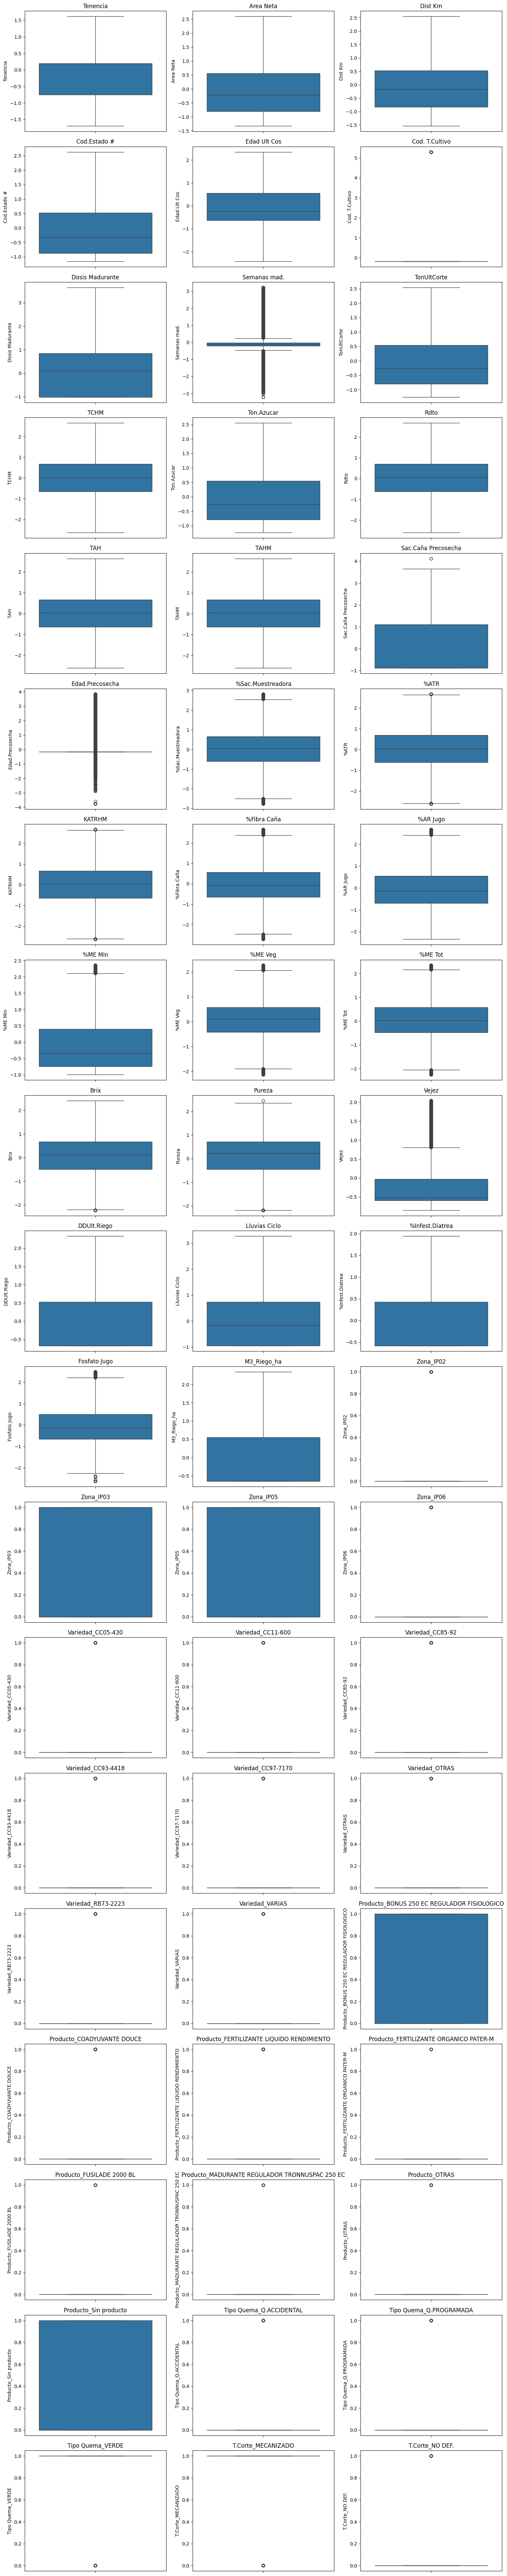

In [33]:
# Boxplots después del preprocesamiento

num_cols = Xt_tr_df.select_dtypes(include=[np.number, "Int64", "Float64"]).columns

n = len(num_cols)
cols = 3
rows = math.ceil(n / cols)

plt.figure(figsize=(15, rows * 4))

for i, col in enumerate(num_cols, 1):
    plt.subplot(rows, cols, i)
    sns.boxplot(y=Xt_tr_df[col], showfliers=True)  # <-- usar X_tr_wins
    plt.title(col)
    plt.xlabel("")

plt.tight_layout()
plt.show()

### **9. Distribución de las variables objetivo (TRAIN)**

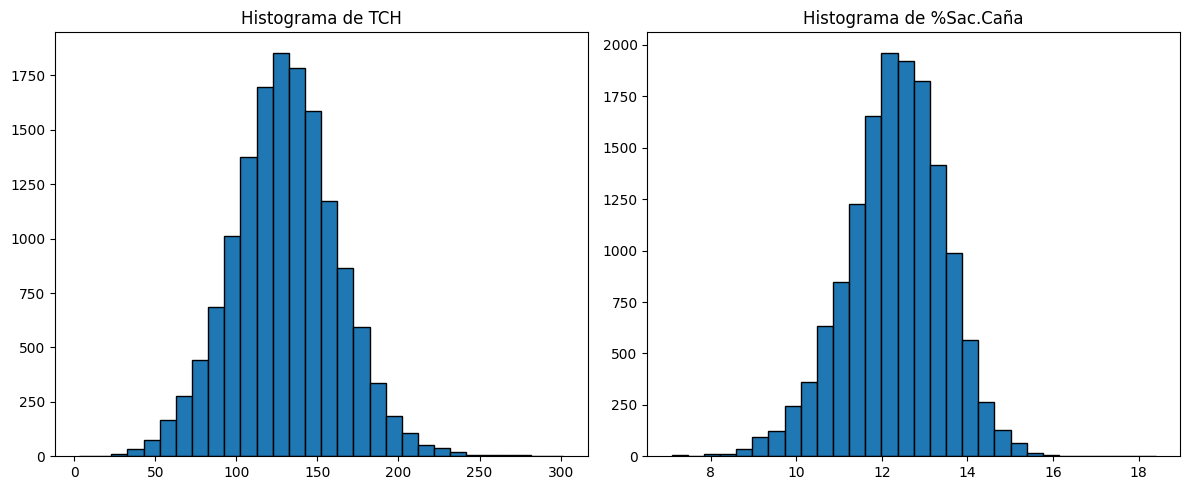

In [34]:
variables = Y_tr[["TCH", "%Sac.Caña"]]

plt.figure(figsize=(12,5))

for i, col in enumerate(variables.columns, 1):
    plt.subplot(1, 2, i)
    plt.hist(variables[col].dropna(), bins=30, edgecolor="black")
    plt.title(f"Histograma de {col}")

plt.tight_layout()
plt.show()

### **10. Matriz de correlaciones**

- Heatmap por bloques para evitar gráficos enormes.
- Heatmap de correlación **solo contra las Y** ordenado por |corr| descendente.

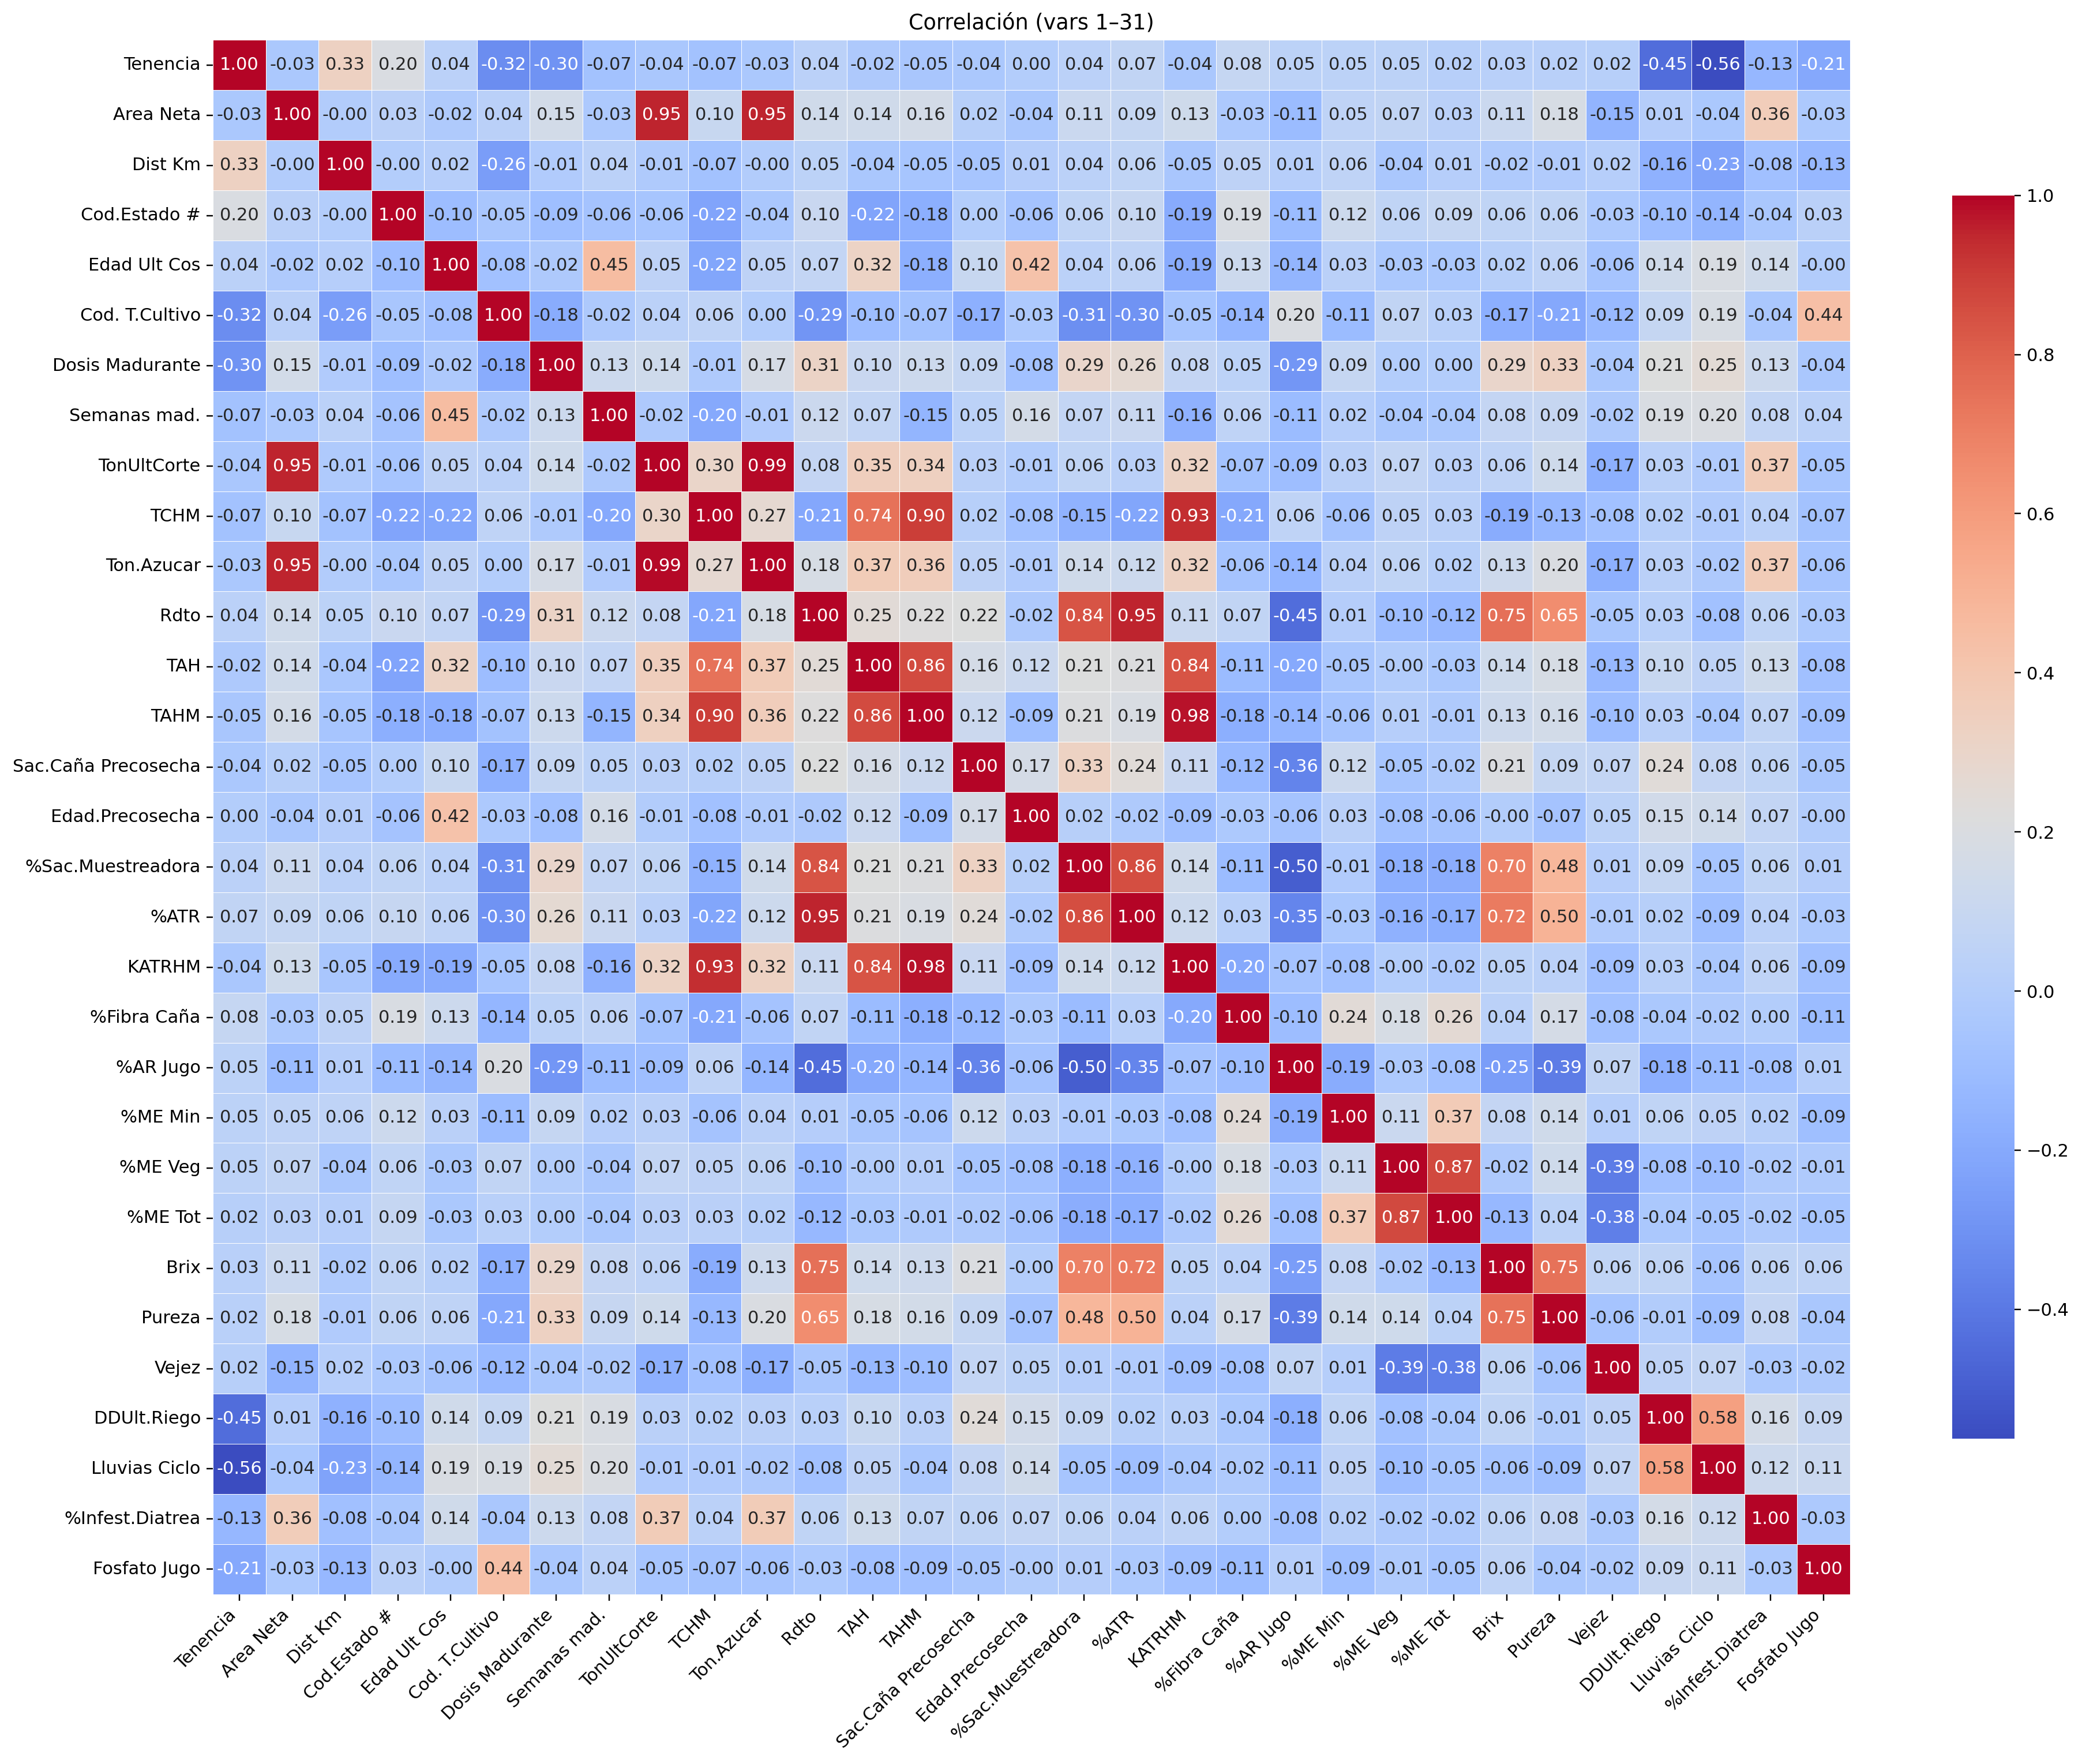

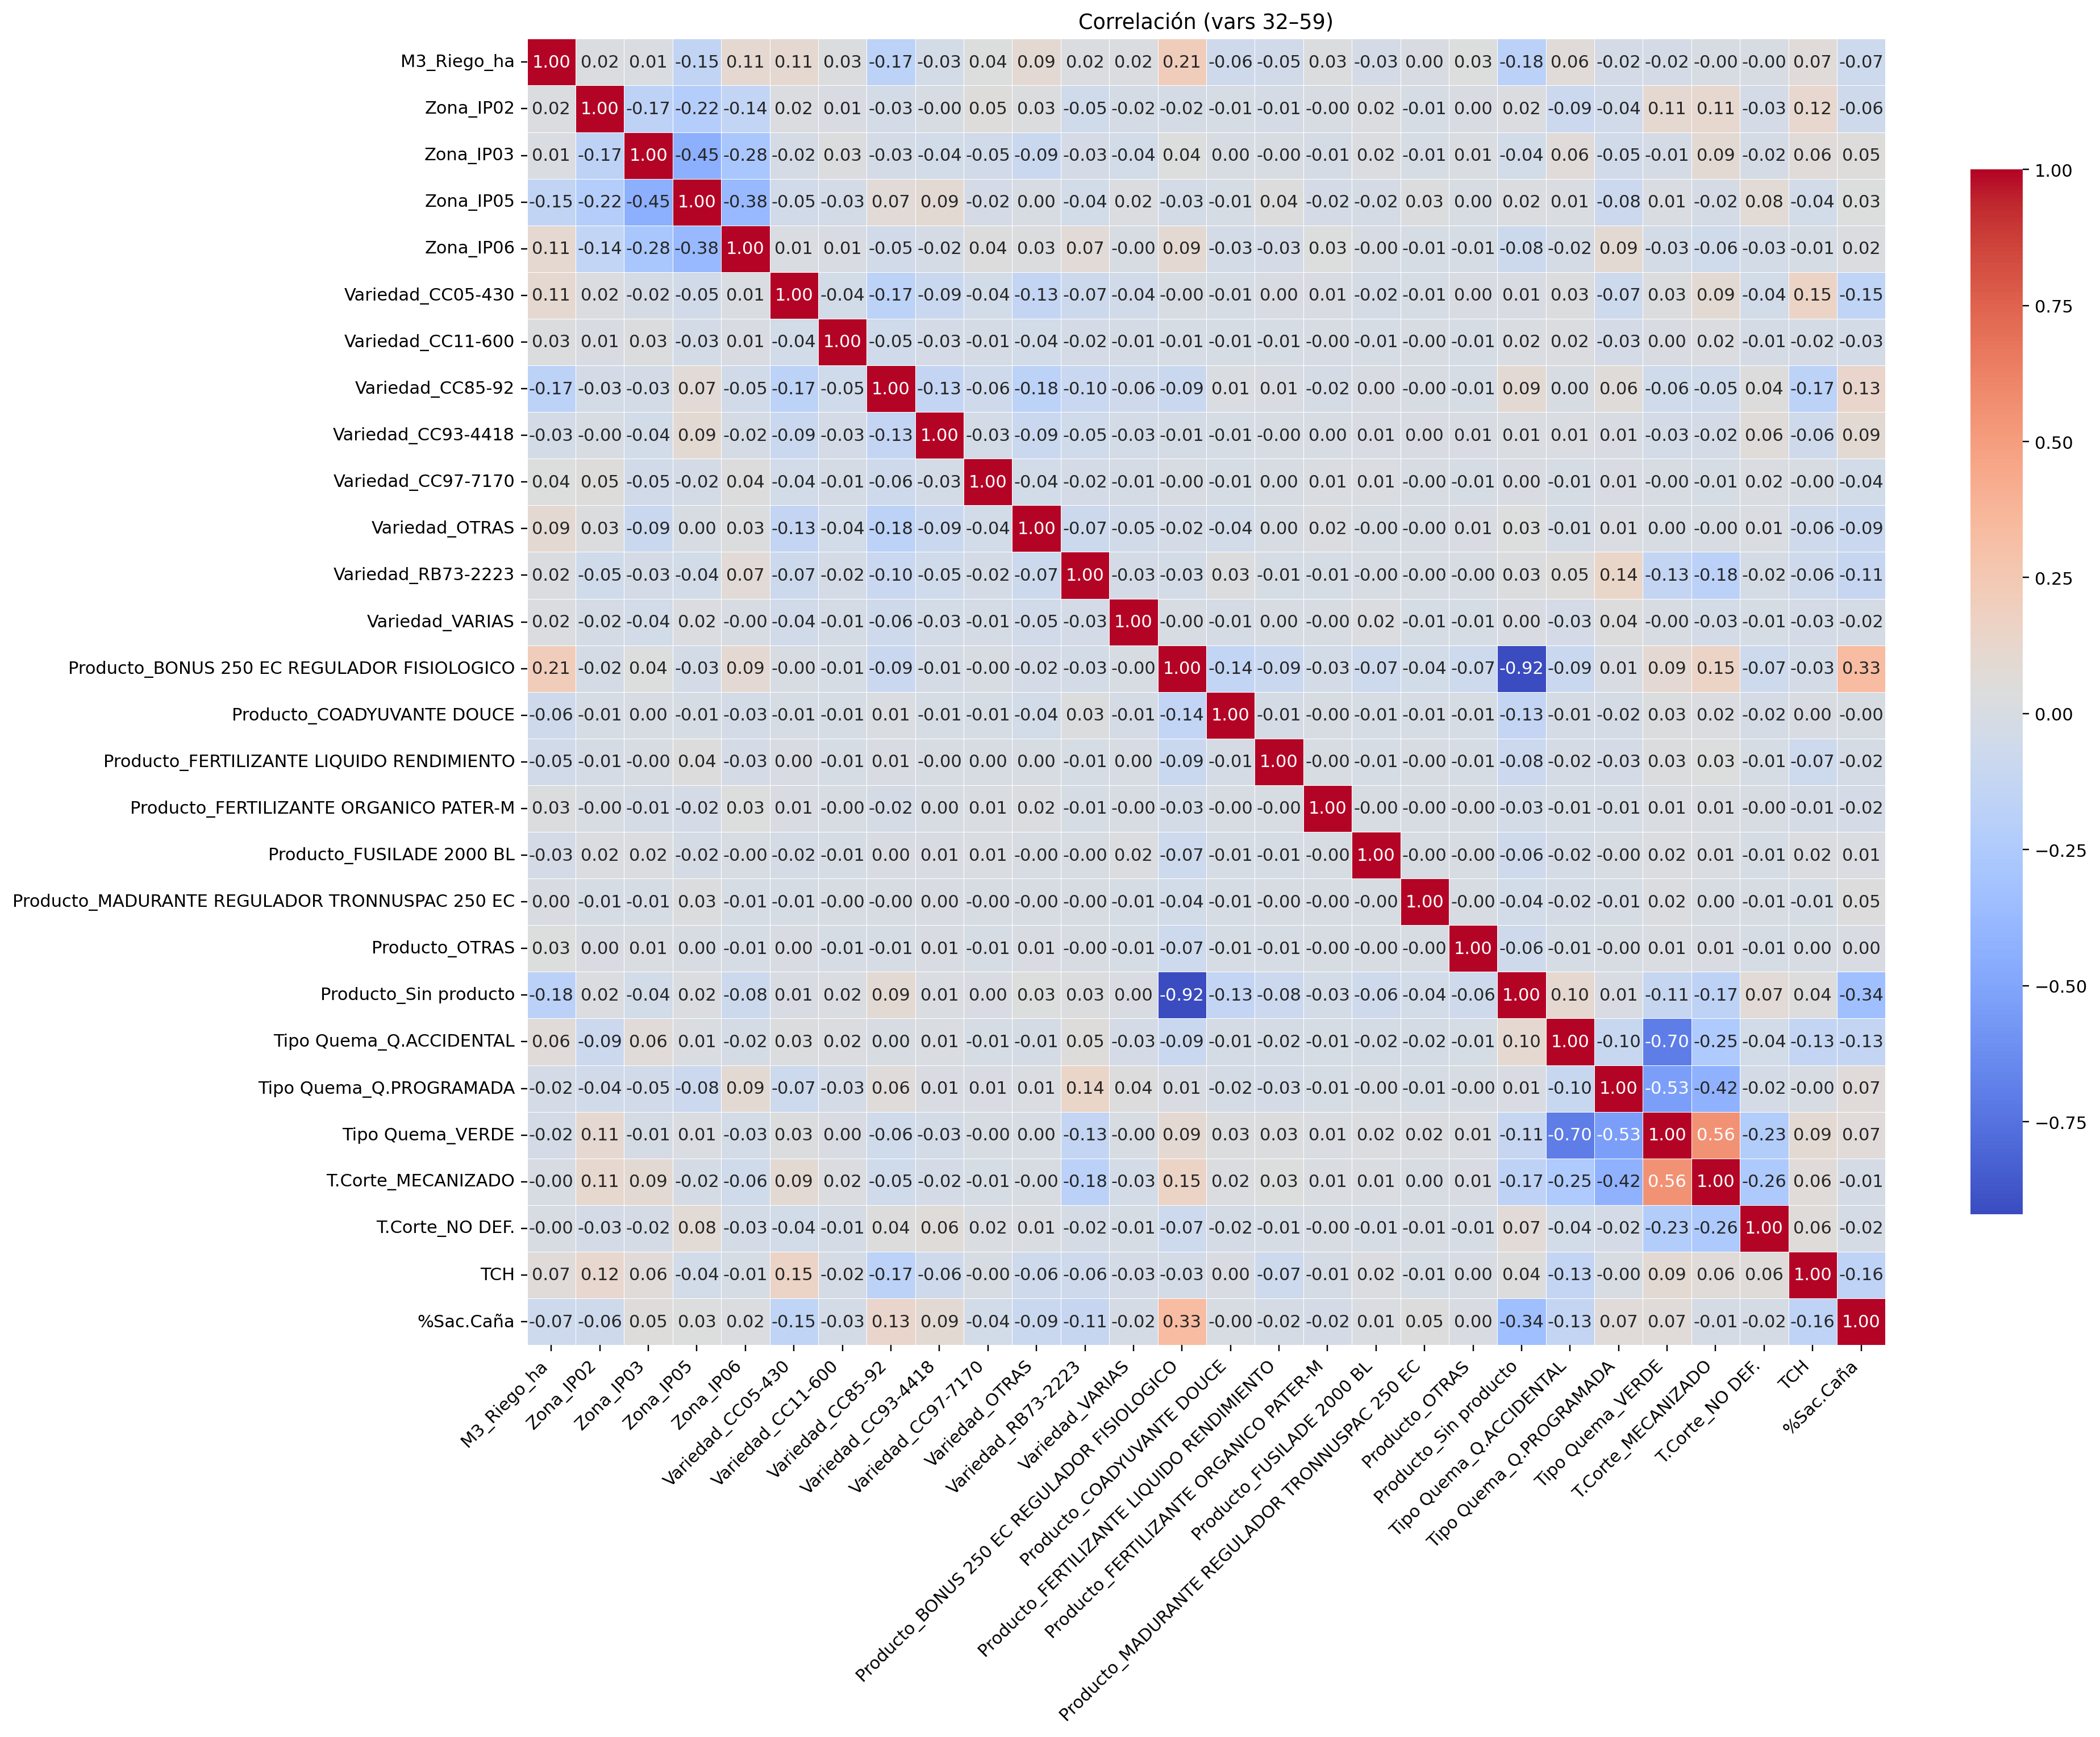

In [35]:
# Correlaciones (concat X transformado + Y)

df_corr = pd.concat([Xt_tr_df, Y_tr[["TCH", "%Sac.Caña"]]], axis=1)

num_cols_corr = df_corr.select_dtypes(include=[np.number, "Int64", "Float64"]).columns
corr = df_corr[num_cols_corr].corr()

# Por bloques

cols = corr.columns.tolist()
step = 31  # tamaño de bloque

for i in range(0, len(cols), step):
    sub = cols[i:i+step]
    corr_sub = corr.loc[sub, sub]


    plt.figure(figsize=(18, 14), dpi=220)
    sns.heatmap(
        corr_sub, annot=True, fmt=".2f", cmap="coolwarm",
        linewidths=0.3, annot_kws={"size": 10}, cbar_kws={"shrink": 0.8}
    )
    plt.xticks(rotation=45, ha="right", fontsize=10)
    plt.yticks(rotation=0, fontsize=10)
    plt.title(f"Correlación (vars {i+1}–{min(i+step, len(cols))})", fontsize=12)
    plt.tight_layout()

    plt.show()

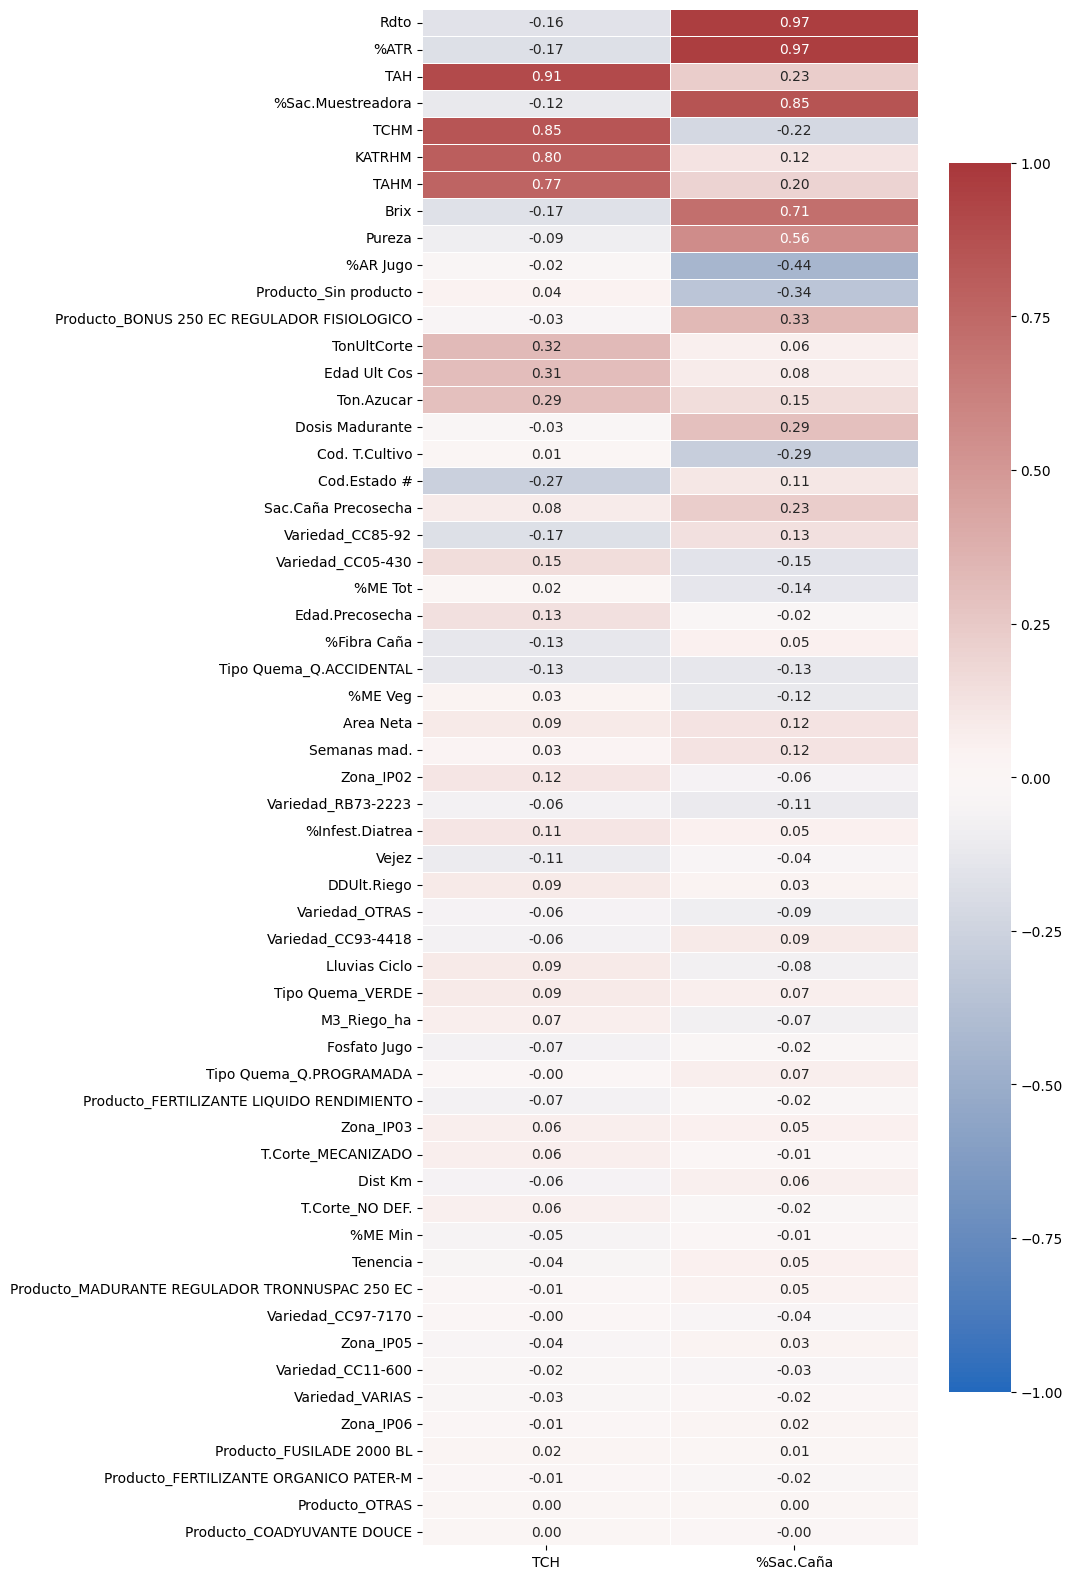

In [36]:
# Solo correlaciones con las variables objetivo

corr_targets = corr.loc[:, y_cols].drop(index=y_cols, errors="ignore")

# Ordenar filas por la mayor |corr| con cualquiera de las Y

order = corr_targets.abs().max(axis=1).sort_values(ascending=False).index
corr_targets = corr_targets.loc[order]

plt.figure(figsize=(8, max(6, 0.35*len(corr_targets))))
sns.heatmap(corr_targets, vmin=-1, vmax=1, center=0, cmap="vlag",
            annot=True, fmt=".2f", linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.show()

### **11. Modelado con scikit-learn (Regresión Lineal)**

- Se eliminan variables objetivo-derivadas para evitar fuga de información.
- Dos pipelines separados: uno por cada objetivo.

Altas correlaciones con TCH (objetivo): TAH, TCHM, KATRHM, TAHM.

Altas correlaciones con %Sac.Caña (objetivo): Rdto, %ATR, %Sac.Muestreadora.

Redundancia en materia extraña: %ME Veg y %ME Tot → Se elimina %ME Veg, mantener %ME Tot.

Redundancia con área: Ton.Azucar, TonUltCorte y Area neta → Se elimina Ton.Azucar y TonUltCorte, mantener Area neta.

Medidas post-cosecha (criterio experto): Brix y Pureza → Se elimina para mitigar riesgo de data leakage.

In [37]:
# Variables a excluir por posible fuga (derivadas de objetivos/azúcar)

cols_drop = ["TAHM","KATRHM","TCHM","TAH","Rdto","%Sac.Muestreadora","%ATR","Brix","Pureza","%ME Veg", "Ton.Azucar", "TonUltCorte"]

X_tr2 = X_tr.drop(columns=cols_drop, errors="ignore")
X_te2 = X_te.drop(columns=cols_drop, errors="ignore")

num_cols = X_tr2.select_dtypes(include=[np.number, "Int64", "Float64"]).columns
cat_cols = X_tr2.select_dtypes(include=["object","string","category","bool"]).columns

# Clonar pipelines para evitar estados previos
num_pipe2 = clone(num_pipe)
cat_pipe2 = clone(cat_pipe)

preprocesamiento = ColumnTransformer([
    ("num", num_pipe2, num_cols),
    ("cat", cat_pipe2, cat_cols),
], remainder="drop")  

# Reutilizamos el mismo preprocessor, cada Pipeline hace su propio fit

pipe_TCH = Pipeline([("prep", clone(preprocesamiento)), ("lr", LinearRegression())])
pipe_SAC = Pipeline([("prep", clone(preprocesamiento)), ("lr", LinearRegression())])

# Entrenar y evaluar en TEST

pipe_TCH.fit(X_tr2, Y_tr["TCH"])
pipe_SAC.fit(X_tr2, Y_tr["%Sac.Caña"])

p_TCH = pipe_TCH.predict(X_te2)
p_SAC = pipe_SAC.predict(X_te2)

print(f"[TCH] RMSE={np.sqrt(mean_squared_error(Y_te['TCH'], p_TCH)):.3f}  "
      f"R2={r2_score(Y_te['TCH'], p_TCH):.3f}")
print(f"[%Sac.Caña] RMSE={np.sqrt(mean_squared_error(Y_te['%Sac.Caña'], p_SAC)):.3f}  "
      f"R2={r2_score(Y_te['%Sac.Caña'], p_SAC):.3f}")

[TCH] RMSE=27.209  R2=0.295
[%Sac.Caña] RMSE=0.924  R2=0.346


In [38]:
set_config(display="diagram") 
display(pipe_TCH)
display(pipe_SAC)

,steps,"[('prep', ...), ('lr', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


,steps,"[('prep', ...), ('lr', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


**Interpretaciones**

**1. Variable objetivo: TCH**

RMSE = 27.209
→ El error cuadrático medio raíz indica que, en promedio, las predicciones se desvían alrededor de 27 Toneladas por hectárea respecto al valor real de TCH. Según la descripción estadistica, el 50% de los datos se encuentran en el Rango de 108 t/ha y 150 t/ha por lo que el error de 27 t/ha es considerable

R² = 0.295
→ El modelo explica apenas un 29.75% de la variabilidad total de TCH. Esto sugiere que la relación capturada es débil o que existen relaciones no lineales que no se han capturado.

Interpretación general: El modelo para TCH tiene baja capacidad explicativa y un error relativamente alto; puede servir como aproximación inicial, pero no es suficientemente robusto para predicciones confiables.

**2. Variable objetivo: %Sac.Caña**

RMSE = 0.924
→ En promedio, el error es de 0.92 puntos porcentuales en la predicción de la sacarosa en caña. EN la distribución explorada en la descripción estadística, evidenciamos que el 50% de los datos estan en el rango de 11% y 13% por lo que el error promedio es relativamente pequeño frente a ese rango

R² = 0.346
→ El modelo explica un 34.6% de la variabilidad. Es un valor bajo-moderado, pero algo mejor que el obtenido para TCH. Indica que hay cierta señal predictiva, aunque aún queda más del 60% de la variabilidad sin explicar.

Interpretación general: El modelo para %Sac.Caña tiene un mejor desempeño relativo (menor error absoluto y mayor R² que en TCH), aunque aún limitado para aplicaciones de predicción de alta precisión.



### **12. Validación cruzada (ShuffleSplit) y Hold-out**

In [39]:
# Definir ShuffleSplit

cv = ShuffleSplit(n_splits=30, test_size=0.2, random_state=42)
scoring = {"rmse": "neg_root_mean_squared_error", "r2": "r2"}

# CV en TRAIN (TCH)
cv_TCH = cross_validate(pipe_TCH, X_tr2, Y_tr["TCH"],
                        cv=cv, scoring=scoring, n_jobs=-1, return_train_score=False)

rmse_tch = -cv_TCH["test_rmse"]
r2_tch   =  cv_TCH["test_r2"]
print(f"[ShuffleSplit CV — TCH]   RMSE = {rmse_tch.mean():.3f} ± {rmse_tch.std():.3f} | R2 = {r2_tch.mean():.3f} ± {r2_tch.std():.3f}")

# CV en TRAIN (%Sac.Caña)
cv_SAC = cross_validate(pipe_SAC, X_tr2, Y_tr["%Sac.Caña"],
                        cv=cv, scoring=scoring, n_jobs=-1, return_train_score=False)

rmse_sac = -cv_SAC["test_rmse"]
r2_sac   =  cv_SAC["test_r2"]
print(f"[ShuffleSplit CV — %Sac]  RMSE = {rmse_sac.mean():.3f} ± {rmse_sac.std():.3f} | R2 = {r2_sac.mean():.3f} ± {r2_sac.std():.3f}")

# Reentrenar en TODO TRAIN y re-evaluar en TEST(hold-out)
pipe_TCH.fit(X_tr2, Y_tr["TCH"])
pipe_SAC.fit(X_tr2, Y_tr["%Sac.Caña"])

p_TCH = pipe_TCH.predict(X_te2)
p_SAC = pipe_SAC.predict(X_te2)

print(f"[TEST TCH]  RMSE={np.sqrt(mean_squared_error(Y_te['TCH'], p_TCH)):.3f}  R2={r2_score(Y_te['TCH'], p_TCH):.3f}")
print(f"[TEST %Sac] RMSE={np.sqrt(mean_squared_error(Y_te['%Sac.Caña'], p_SAC)):.3f}  R2={r2_score(Y_te['%Sac.Caña'], p_SAC):.3f}")

[ShuffleSplit CV — TCH]   RMSE = 27.668 ± 0.383 | R2 = 0.276 ± 0.013
[ShuffleSplit CV — %Sac]  RMSE = 0.911 ± 0.016 | R2 = 0.371 ± 0.017
[TEST TCH]  RMSE=27.209  R2=0.295
[TEST %Sac] RMSE=0.924  R2=0.346


**Interpretaciones**

**1. Variable objetivo: TCH**

Validación cruzada (ShuffleSplit CV):

RMSE = 27.668 ± 0.383

R² = 0.276 ± 0.013

Conjunto de prueba (TEST):

RMSE = 27.209

R² = 0.295

- El error promedio en CV **27.6 t/ha** es muy cercano al del conjunto de prueba **27.2 t/ha**, con una desviación pequeña **±0.38**. Esto muestra que el modelo es estable y consistente entre entrenamiento y prueba lo que evidencia ausencia de sobreajuste.

Sin embargo, la capacidad explicativa sigue siendo baja **29.5%**, lo que limita su utilidad para predicciones robustas.

**2. Variable objetivo: %Sac.Caña**

Validación cruzada (ShuffleSplit CV):

RMSE = 0.911 ± 0.016

R² = 0.371 ± 0.017

Conjunto de prueba (TEST):

RMSE = 0.924

R² = 0.346

- Los resultados de CV y de prueba son muy cercanos, lo que evidencia un buen grado de generalización.

El error **0.92 p.p.** es pequeño en relación con el rango intercuartílico del %Sac.Caña (11%–13%), lo que hace que el modelo sea razonablemente útil como predictor.

No obstante, el R² se mantiene en un nivel moderado **34.6%**, por lo que aún queda más del 60% de la variabilidad sin explicar.

### **13. OLS con statsmodels (para diagnóstico e inferencia)**

- Usamos **exactamente el mismo preprocesamiento** ajustado en TRAIN.
- Ajustamos OLS con `statsmodels` para obtener **resúmenes clásicos**.

In [40]:
# 1) Ajusta el preprocesador SOLO con TRAIN
preprocesamiento.fit(X_tr2)

# 2) Transforma X_tr2
Xtr_t = preprocesamiento.transform(X_tr2)

# 3) DataFrame con nombres de features
feat_names = preprocesamiento.get_feature_names_out()
Xtr_arr = Xtr_t.toarray() if hasattr(Xtr_t, "toarray") else np.asarray(Xtr_t)
Xtr_df  = pd.DataFrame(Xtr_arr, columns=feat_names, index=X_tr2.index)

# 4) Agrega constante
Xtr_df_c = sm.add_constant(Xtr_df, has_constant='add')

# 5) OLS por objetivo
y_tch = Y_tr.loc[X_tr2.index, "TCH"].astype(float)
y_sac = Y_tr.loc[X_tr2.index, "%Sac.Caña"].astype(float)

ols_TCH = sm.OLS(y_tch, Xtr_df_c).fit()
ols_SAC = sm.OLS(y_sac, Xtr_df_c).fit()

print(ols_TCH.summary())
print(ols_SAC.summary())



                            OLS Regression Results                            
Dep. Variable:                    TCH   R-squared:                       0.286
Model:                            OLS   Adj. R-squared:                  0.284
Method:                 Least Squares   F-statistic:                     127.6
Date:                Thu, 18 Sep 2025   Prob (F-statistic):               0.00
Time:                        09:02:38   Log-Likelihood:                -68156.
No. Observations:               14403   AIC:                         1.364e+05
Df Residuals:                   14357   BIC:                         1.368e+05
Df Model:                          45                                         
Covariance Type:            nonrobust                                         
                                                          coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------

**Interpretaciones**

**1. TCH — señales principales**

↑ TCH

Edad Últ. Cosecha: Coef = +11.87, t = 38.32, P < 0.001 — una de las señales más fuertes.

Área Neta: Coef = +1.68, t = 6.33, P < 0.001.

M3_Riego_ha: Coef = +1.78, t = 5.48, P < 0.001.

Lluvias Ciclo: Coef = +1.28, t = 3.82, P < 0.001.

Sac. Caña Precosecha: Coef = +2.69, t = 9.58, P < 0.001 — consistente: mayor sacarosa previa suele anticipar mejor desempeño.

%ME Tot: Coef = +1.77, t = 5.44, P < 0.001.

Tenencia: Coef = +1.64, t = 4.69, P < 0.001.

DDÚlt. Riego: Coef = +0.83, t = 2.65, P = 0.008.

%Infest. Diatraea: Coef = +0.52, t = 2.01, P = 0.045 (marginal).

Cod. T. Cultivo: Coef = +0.61, t = 1.97, P = 0.049 (marginal).

↓ TCH

Semanas mad.: Coef = −4.39, t = −16.35, P < 0.001.

%Fibra Caña: Coef = −4.22, t = −15.91, P < 0.001.

Dist Km: Coef = −4.82, t = −13.80, P < 0.001.

Cod. Estado #: Coef = −3.45, t = −10.52, P < 0.001.

Fosfato Jugo: Coef = −2.08, t = −7.82, P < 0.001.

Vejez: Coef = −2.03, t = −5.67, P < 0.001.

%AR Jugo: Coef = −0.89, t = −3.20, P = 0.001.

Edad Precosecha: Coef = −0.57, t = −2.17, P = 0.030.

P-valores altos (sin evidencia fuerte en TCH): %ME Min (P = 0.789), Dosis Madurante (P = 0.142), varios productos y modalidades de corte.

TCH responde fuerte a estado fisiológico y logística (edad, fibra, semanas de maduración, distancia), agua (riego/lluvias) y genética/zona (variedad/ubicación).

**2. %Sac.Caña — señales principales**

↑ %Sac

Semanas mad.: Coef = +0.080, t = 9.03, P < 0.001.

Sac. Caña Precosecha: Coef = +0.081, t = 8.75, P < 0.001.

Fosfato Jugo: Coef = +0.078, t = 8.96, P < 0.001.

Área Neta: Coef = +0.059, t = 6.69, P < 0.001.

Tipo Quema VERDE: Coef = +0.581, t = 8.08, P < 0.001.

%Fibra Caña: Coef = +0.025, t = 2.89, P = 0.004.

Vejez: Coef = +0.025, t = 2.10, P = 0.036.

Producto: Madurante TRONNUSPAC 250 EC: Coef = +1.057, t = 4.48, P < 0.001.

Producto: BONUS 250 EC: Coef = +0.329, t = 2.19, P = 0.029.

Variedad CC93-4418: Coef = +0.215, t = 6.28, P < 0.001.

Variedad CC85-92: Coef = +0.062, t = 2.18, P = 0.029.

↓ %Sac

%AR Jugo: Coef = −0.330, t = −35.88, P < 0.001 — efecto más fuerte y esperado.

%ME Tot: Coef = −0.282, t = −26.27, P < 0.001.

Cod. T. Cultivo: Coef = −0.199, t = −19.35, P < 0.001.

Lluvias Ciclo: Coef = −0.158, t = −14.27, P < 0.001.

T. Corte MECANIZADO: Coef = −0.260, t = −9.62, P < 0.001.

Edad Precosecha: Coef = −0.044, t = −5.05, P < 0.001.

Variedad RB73-2223: Coef = −0.432, t = −10.56, P < 0.001.

Variedad CC97-7170: Coef = −0.186, t = −2.80, P = 0.005.

Variedad OTRAS: Coef = −0.159, t = −5.94, P < 0.001.

Variedad CC05-430: Coef = −0.144, t = −5.18, P < 0.001.

Zona IP02: Coef = −0.106, t = −2.83, P = 0.005.

Dist Km: Coef = −0.025, t = −2.20, P = 0.028.

%Infest. Diatraea: Coef = −0.018, t = −2.18, P = 0.029.

P-valores altos (sin evidencia fuerte en %Sac): M3_Riego_ha (P = 0.259), Edad Últ. Cosecha (P = 0.553), Tenencia (P = 0.866), varias dummies de productos y zonas.

%Sac se alinea con madurez (semanas), calidad de jugo (%AR), limpieza (%ME Tot) y manejo/cosecha (tipo de corte, quema verde).


**En general**

Ajuste global: 

TCH -> 𝑅2 0.29

%Sac.Caña -> 𝑅2 0.377

Coherente con lo vimos en TEST/CV: se capta señal, pero hay alta variabilidad no explicada.

Modelo global significativo: F-stat con 𝑝 < 0.001 en ambos → el conjunto de predictores aporta.

### **14. Regularización: Lasso y Ridge**

- **LassoCV**: selección de variables vía L1.
- **RidgeCV**: estabiliza coeficientes con colinealidad.

#### **14.1 Regularización Lasso**

In [41]:
# Grid de alphas razonable para datos escalados
alphas = np.logspace(-4, 1, 60) 
lasso_kwargs = dict(alphas=alphas, cv=5, n_jobs=-1, random_state=42, max_iter=25000)

# Pipelines por objetivo (reutilizando el mismo preprocesador)
pipe_lasso_TCH = Pipeline([("prep", clone(preprocesamiento)), ("model", LassoCV(**lasso_kwargs))])
pipe_lasso_SAC = Pipeline([("prep", clone(preprocesamiento)), ("model", LassoCV(**lasso_kwargs))])

# Entrenar
pipe_lasso_TCH.fit(X_tr2, Y_tr["TCH"])
pipe_lasso_SAC.fit(X_tr2, Y_tr["%Sac.Caña"])

# Predecir
pred_TCH_las = pipe_lasso_TCH.predict(X_te2)
pred_SAC_las = pipe_lasso_SAC.predict(X_te2)

# Métricas
rmse_TCH = float(np.sqrt(mean_squared_error(Y_te["TCH"], pred_TCH_las)))
r2_TCH   = float(r2_score(Y_te["TCH"], pred_TCH_las))
rmse_SAC = float(np.sqrt(mean_squared_error(Y_te["%Sac.Caña"], pred_SAC_las)))
r2_SAC   = float(r2_score(Y_te["%Sac.Caña"], pred_SAC_las))

print(f"[Lasso TCH]      α*={pipe_lasso_TCH.named_steps['model'].alpha_:.6f}  RMSE={rmse_TCH:.3f}  R2={r2_TCH:.3f}")
print(f"[Lasso %Sac.Caña] α*={pipe_lasso_SAC.named_steps['model'].alpha_:.6f}  RMSE={rmse_SAC:.3f}  R2={r2_SAC:.3f}")

[Lasso TCH]      α*=0.000148  RMSE=27.209  R2=0.295
[Lasso %Sac.Caña] α*=0.000392  RMSE=0.923  R2=0.346


**Interpretaciones**

**1. TCH**

α∗= 0.000148: valor muy pequeño → el modelo penaliza poco, por lo tanto conserva la mayoría de variables.

RMSE = 27.209: error cuadrático medio en la misma escala de TCH. Muy similar al encontrado en Regresión lineal sin regularización

R² = 0.295: muy cercano al OLS (0.286).

Lasso no mejora sustancialmente el ajuste, pero sirve como filtro para atenuar variables poco relevantes y reducir riesgo de sobreajuste.

**2. %Sac.Caña**

𝛼∗ = 0.000392: mayor que en TCH, indica que se aplica más regularización.

RMSE = 0.923: error cuadrático medio en puntos porcentuales de sacarosa. Igualmente, similar al encontrado en Regresión lineal sin regularización

R² = 0.346: algo menor que el OLS (0.377).

El modelo sacrifica algo de ajuste (R² más bajo) a cambio de mayor parsimonia.

In [42]:
# Interceptos y coeficientes Lasso (alineados con features)

# TCH
m_tch = pipe_lasso_TCH.named_steps["model"]
f_tch = pipe_lasso_TCH.named_steps["prep"].get_feature_names_out()
print(f"[Lasso TCH]  intercepto = {float(m_tch.intercept_):.6f}")

coef_tch = pd.Series(m_tch.coef_, index=f_tch, name="beta_TCH")
print("\nCoeficientes TCH:")
print(coef_tch.sort_values(ascending=False))

# %Sac.Caña
m_sac = pipe_lasso_SAC.named_steps["model"]
f_sac = pipe_lasso_SAC.named_steps["prep"].get_feature_names_out()
print(f"\n[Lasso %Sac.Caña] intercepto = {float(m_sac.intercept_):.6f}")

coef_sac = pd.Series(m_sac.coef_, index=f_sac, name="beta_%Sac.Caña")
print("\nCoeficientes %Sac.Caña:")
print(coef_sac.sort_values(ascending=False))

[Lasso TCH]  intercepto = 133.795614

Coeficientes TCH:
cat__Zona_IP02                                         22.496962
cat__Zona_IP03                                         20.852473
cat__Zona_IP05                                         19.117706
cat__Zona_IP06                                         12.067703
num__Edad Ult Cos                                      11.870870
cat__Variedad_CC05-430                                 11.564766
num__Sac.Caña Precosecha                                2.694405
cat__T.Corte_NO DEF.                                    2.621619
num__M3_Riego_ha                                        1.776785
num__%ME Tot                                            1.772888
num__Area Neta                                          1.683019
num__Tenencia                                           1.638612
cat__Tipo Quema_Q.PROGRAMADA                            1.634121
cat__T.Corte_MECANIZADO                                 1.300172
num__Lluvias Ciclo                

**Interpretaciones**

**1. TCH — señales principales** 

↑ TCH

Zonas: IP02 +22.50, IP03 +20.85, IP05 +19.12, IP06 +12.07 → fuertes relaciones geográficas/ambientales.

Edad Últ. Cosecha: +11.87 → estado fisiológico dominante.

Variedad CC05-430: +11.56 → ventaja en variedad.

Sac. Caña Precosecha: +2.69 → mayor “madurez” previa se asocia con más TCH.

Operación/agua: T.Corte NO DEF. +2.62, M3_Riego_ha +1.78, %ME Tot +1.77, Área Neta +1.68, Tenencia +1.64, Quema Programada +1.63, Corte Mecanizado +1.30, Lluvias Ciclo +1.28, DDÚlt.Riego +0.83, Cod. T.Cultivo +0.61, %Infest. Diatraea +0.52.

↓ TCH

%ME Min −0.07 (pequeño).

Edad Precosecha −0.57, Quema Accidental −0.84, %AR Jugo −0.89, Dosis Madurante −0.94.

Vejez −2.03, Fosfato Jugo −2.08, Quema VERDE −3.15.

Cod. Estado # −3.45, %Fibra Caña −4.22, Semanas mad. −4.39, Dist Km −4.82 (penalización logística).

Gran parte del rendimiento se explica por ubicación (Zonas), Edad y decisiones agronómicas. Penalizan distancia, semanas extra de maduración, fibra y algunos productos.

**2. %Sac. Caña — señales principales** 

↑ %Sac

Madurante TRONNUSPAC 250 EC +0.774 (asociación positiva fuerte).

Tipo Quema VERDE +0.546.

Producto BONUS 250 EC +0.270.

Variedad CC93-4418 +0.210.

T.Corte NO DEF. +0.120.

Sac. Caña Precosecha +0.082, Semanas mad. +0.079, Fosfato Jugo +0.077.

Cod. Estado # +0.064, Variedad CC85-92 +0.062, Área Neta +0.059, Zona IP03 +0.055.

%Fibra Caña +0.024, Vejez +0.022, M3_Riego_ha +0.011, Edad Últ. Cosecha +0.007, DDÚlt.Riego +0.004 (pequeños).

↓ %Sac

Tenencia −0.001 (nulo), %Infest. Diatraea −0.018, Dist Km −0.023, VARIAS −0.029, %ME Min −0.029.

Zonas: IP05 −0.034, IP06 −0.039, IP02 −0.092.

Edad Precosecha −0.043, Dosis Madurante −0.046, Quema Accidental −0.049.

Clima/proceso: Lluvias Ciclo −0.155, Cod. T.Cultivo −0.198, T. Corte MECANIZADO −0.258, %ME Tot −0.281, Sin producto −0.331, %AR Jugo −0.331 (los dos últimos: señales fuertes de menor sacarosa).

Varias dummies de producto quedan en 0 (apagadas) → Lasso favorece parsimonia y deja lo más informativo.

%Sac aumenta con madurez (semanas, precosecha) y ciertas prácticas (quema verde) y productos (TRONNUSPAC, BONUS). Disminuye con %AR Jugo y %ME Tot (calidad/limpieza del jugo), corte mecanizado y algunas variedades y zonas.


In [43]:
display(pipe_lasso_TCH)
display(pipe_lasso_SAC)

,steps,"[('prep', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


,steps,"[('prep', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


#### **14.2 Regularización Ridge**

In [44]:
pipe_ridge_TCH = Pipeline([("prep", clone(preprocesamiento)), ("model", RidgeCV(alphas=alphas, cv=5))])
pipe_ridge_SAC = Pipeline([("prep", clone(preprocesamiento)), ("model", RidgeCV(alphas=alphas, cv=5))])

pipe_ridge_TCH.fit(X_tr2, Y_tr["TCH"])
pipe_ridge_SAC.fit(X_tr2, Y_tr["%Sac.Caña"])

pred_TCH = pipe_ridge_TCH.predict(X_te2)
pred_SAC = pipe_ridge_SAC.predict(X_te2)

print(f"[Ridge TCH]      α*={pipe_ridge_TCH.named_steps['model'].alpha_:.6f}  "
      f"RMSE={np.sqrt(mean_squared_error(Y_te['TCH'], pred_TCH)):.3f}  R2={r2_score(Y_te['TCH'], pred_TCH):.3f}")
print(f"[Ridge %Sac.Caña] α*={pipe_ridge_SAC.named_steps['model'].alpha_:.6f}  "
      f"RMSE={np.sqrt(mean_squared_error(Y_te['%Sac.Caña'], pred_SAC)):.3f}  R2={r2_score(Y_te['%Sac.Caña'], pred_SAC):.3f}")

[Ridge TCH]      α*=0.362512  RMSE=27.208  R2=0.295
[Ridge %Sac.Caña] α*=5.568814  RMSE=0.924  R2=0.346


TCH: Ridge y Lasso mantienen prácticamente el mismo desempeño que OLS, con un leve aumento en R² (+0.01).

%Sac: Ridge y Lasso reducen un poco el R² respecto a OLS (0.346 vs. 0.377), pero ganan en estabilidad y robustez.

In [45]:
# Coeficientes Ridge

feat_TCH = pipe_ridge_TCH.named_steps["prep"].get_feature_names_out()
feat_SAC = pipe_ridge_SAC.named_steps["prep"].get_feature_names_out()
coef_TCH = pd.Series(pipe_ridge_TCH.named_steps["model"].coef_, index=feat_TCH, name="beta_TCH")
coef_SAC = pd.Series(pipe_ridge_SAC.named_steps["model"].coef_, index=feat_SAC, name="beta_%Sac.Caña")
print("\nCoeficientes TCH:\n", coef_TCH.sort_values(ascending=False))
print("\nCoeficientes %Sac.Caña (|β|):\n", coef_SAC.sort_values(ascending=False))


Coeficientes TCH:
 cat__Zona_IP02                                         22.471973
cat__Zona_IP03                                         20.827361
cat__Zona_IP05                                         19.099081
cat__Zona_IP06                                         12.048077
num__Edad Ult Cos                                      11.870244
cat__Variedad_CC05-430                                 11.559179
num__Sac.Caña Precosecha                                2.698009
cat__T.Corte_NO DEF.                                    2.651523
num__M3_Riego_ha                                        1.775977
num__%ME Tot                                            1.772566
num__Area Neta                                          1.683746
num__Tenencia                                           1.641315
cat__Tipo Quema_Q.PROGRAMADA                            1.631959
cat__T.Corte_MECANIZADO                                 1.308071
num__Lluvias Ciclo                                      1.275152
num__

**Interpretaciones**

**1. TCH — señales principales**

↑ TCH

Zonas (premios grandes): IP02 +22.47, IP03 +20.83, IP05 +19.10, IP06 +12.05 → ubicación/ambiente pesan mucho.

Estado fenológico: Edad Últ. Cosecha +11.87

Madurez/agua/escala: Sac. Caña Precosecha +2.70, M3_Riego_ha +1.78, %ME Tot +1.77, Área Neta +1.68, Tenencia +1.64, Lluvias ciclo +1.28, DDUlt.Riego +0.83.

Operación: Corte NO DEF. +2.65, Corte mecanizado +1.31, Quema programada +1.63.

↓ TCH

Logística/tiempo/fibra: Distancia −4.81, Semanas mad. −4.39, %Fibra −4.22.

Condición/estado: Cod. Estado # −3.45, Quema VERDE −3.16, Vejez −2.04, Fosfato Jugo −2.08, %AR Jugo −0.89, Edad Precosecha −0.57.

Se ratifica el patrón visto con OLS/Lasso: zona y edad/variedad dominan; penalizan distancia, maduración prolongada y fibra. Las dummies de producto con coeficientes negativos probablemente reflejan uso en lotes con problemas (correlación ≠ causalidad).


**2. %Sac.Caña — señales principales**

↑ %Sac

Prácticas/insumos específicos: TRONNUSPAC +0.803, Quema VERDE +0.558, BONUS 250 EC +0.255.

Madurez/proceso: Sac. Caña Precosecha +0.081, Semanas mad. +0.080, Fosfato Jugo +0.078.

Operación: Corte NO DEF. +0.157.

↓ %Sac

Calidad/limpieza del jugo: %AR Jugo −0.331, %ME Tot −0.282, %ME Min −0.029.

Operación: Corte mecanizado −0.259, Quema accidental −0.047.

Clima/proceso: Lluvias ciclo −0.157, Cod. T. Cultivo −0.199.

Genética/Zona: RB73-2223 −0.427, CC97-7170 −0.181, CC05-430 −0.143, OTRAS −0.157, IP02 −0.104, IP05 −0.043, IP06 −0.048.

Otros: Sin producto −0.353, Distancia −0.025, Edad Precosecha −0.044, Dosis Madurante −0.049.

Sube con madurez (semanas, precosecha) y con quema verde/insumo TRONNUSPAC; cae con %AR y materia extraña (limpieza), con corte mecanizado y con algunas variedades/zonas.


In [46]:
display(pipe_ridge_TCH)
display(pipe_ridge_SAC)

,steps,"[('prep', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


,steps,"[('prep', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


### **15. Multicolinealidad: VIF**

- Calculamos VIF sobre **features numéricas** transformadas.
- Eliminamos varianza cero para evitar `inf`.

In [47]:
# Matriz de features transformadas (ya creada como Xtr_df)

Xtr_arr = Xtr_t.toarray() if hasattr(Xtr_t, "toarray") else Xtr_t
Xtr_df  = pd.DataFrame(Xtr_arr, columns=feat_names, index=X_tr2.index)


# Calcular VIF
vif_series = pd.Series(
    [variance_inflation_factor(Xtr_df.values, i) for i in range(Xtr_df.shape[1])],
    index=Xtr_df.columns,
    name="VIF"
).sort_values(ascending=False)

print(vif_series.head(25))

cat__Tipo Quema_VERDE                               59.724190
cat__Producto_Sin producto                          45.837841
cat__Producto_BONUS 250 EC REGULADOR FISIOLOGICO    42.289338
cat__Tipo Quema_Q.ACCIDENTAL                        10.817565
cat__T.Corte_MECANIZADO                             10.475696
num__Dosis Madurante                                 7.212735
cat__Tipo Quema_Q.PROGRAMADA                         6.997329
cat__Zona_IP05                                       6.694015
cat__Zona_IP03                                       5.747883
cat__Zona_IP06                                       3.201948
cat__Variedad_CC85-92                                2.777667
cat__Producto_COADYUVANTE DOUCE                      2.509735
num__Vejez                                           2.451152
num__Tenencia                                        2.316877
num__Dist Km                                         2.302195
num__Lluvias Ciclo                                   2.131189
num__Cod

**Interpretación de la multicolinealidad (VIF):**

Los resultados muestran multicolinealidad muy alta en algunas variables, especialmente en las dummies de tipo de quema y de ciertos productos (con VIF entre 40 y 60). Esto indica que esas variables están fuertemente correlacionadas con otras del modelo, lo cual puede hacer que los coeficientes estimados sean inestables y los niveles de significancia poco confiables.

En niveles moderados (VIF 5–7) aparecen variables como Dosis Madurante y algunas zonas, lo que sugiere relaciones fuertes pero no críticas.

Es importante destacar que, en este tipo de modelos, las dummies tienden a inflar artificialmente el VIF, sobre todo cuando hay categorías poco frecuentes.

In [48]:
# VIF solo en numéricas del preprocesador
num_mask = Xtr_df.columns.str.startswith("num__")
X_num = Xtr_df.loc[:, num_mask].copy()

# Eliminar varianza cero
var0 = X_num.columns[(X_num.var(axis=0) == 0)]
if len(var0):
    X_num = X_num.drop(columns=var0)

# Calcula VIF
vif_series_num = pd.Series(
    [variance_inflation_factor(X_num.values, i) for i in range(X_num.shape[1])],
    index=X_num.columns,
    name="VIF_num"
).sort_values(ascending=False)

print(vif_series_num.head(25))

num__Tenencia               2.222994
num__Lluvias Ciclo          2.038094
num__M3_Riego_ha            1.958551
num__DDUlt.Riego            1.842402
num__Cod. T.Cultivo         1.667008
num__Edad Ult Cos           1.666800
num__%ME Tot                1.471782
num__Dosis Madurante        1.401149
num__%AR Jugo               1.359834
num__Semanas mad.           1.337600
num__%ME Min                1.316115
num__Sac.Caña Precosecha    1.308470
num__Vejez                  1.296977
num__Fosfato Jugo           1.293877
num__Edad.Precosecha        1.279076
num__%Infest.Diatrea        1.249836
num__Area Neta              1.248397
num__%Fibra Caña            1.230088
num__Dist Km                1.199533
num__Cod.Estado #           1.145229
Name: VIF_num, dtype: float64


**Interpretación de la multicolinealidad (VIF solo numéricas):**

Los resultados muestran que ninguna variable numérica presenta un VIF preocupante. Todos los valores están por debajo de 2.5.

Más altos (pero bajos en términos absolutos): Tenencia (2.22), Lluvias Ciclo (2.04) y M3_Riego_ha (1.96). Sugieren correlaciones moderadas entre variables relacionadas con escala y condiciones hídricas, pero no comprometen la estabilidad del modelo.

Resto de variables: Todas entre 1.1 y 1.7, lo cual indica que son prácticamente independientes y aportan información complementaria.


In [49]:
tbl = pd.DataFrame({
    "Modelo":   ["OLS","LassoCV","RidgeCV"],
    "TCH R²":   [r2_score(Y_te["TCH"], p_TCH), r2_TCH, r2_score(Y_te["TCH"], pred_TCH)],
    "TCH RMSE": [np.sqrt(mean_squared_error(Y_te["TCH"], p_TCH)), 
                 rmse_TCH, 
                 np.sqrt(mean_squared_error(Y_te["TCH"], pred_TCH))],
    "TCH MAE":  [mean_absolute_error(Y_te["TCH"], p_TCH),
                 mean_absolute_error(Y_te["TCH"], pred_TCH_las),
                 mean_absolute_error(Y_te["TCH"], pred_TCH)],
    "%Sac R²":  [r2_score(Y_te["%Sac.Caña"], p_SAC), 
                 r2_SAC, 
                 r2_score(Y_te["%Sac.Caña"], pred_SAC)],
    "%Sac RMSE":[np.sqrt(mean_squared_error(Y_te["%Sac.Caña"], p_SAC)), 
                 rmse_SAC, 
                 np.sqrt(mean_squared_error(Y_te["%Sac.Caña"], pred_SAC))],
    "%Sac MAE": [mean_absolute_error(Y_te["%Sac.Caña"], p_SAC),
                 mean_absolute_error(Y_te["%Sac.Caña"], pred_SAC_las),
                 mean_absolute_error(Y_te["%Sac.Caña"], pred_SAC)],
})

print(tbl.to_markdown(index=False, floatfmt=".3f"))

| Modelo   |   TCH R² |   TCH RMSE |   TCH MAE |   %Sac R² |   %Sac RMSE |   %Sac MAE |
|:---------|---------:|-----------:|----------:|----------:|------------:|-----------:|
| OLS      |    0.295 |     27.209 |    20.949 |     0.346 |       0.924 |      0.712 |
| LassoCV  |    0.295 |     27.209 |    20.948 |     0.346 |       0.923 |      0.712 |
| RidgeCV  |    0.295 |     27.208 |    20.948 |     0.346 |       0.924 |      0.712 |


### **Cuadro comparativo**

| Modelo   |   TCH R² |   TCH RMSE |   TCH MAE |   %Sac R² |   %Sac RMSE |   %Sac MAE |
|:---------|---------:|-----------:|----------:|----------:|------------:|-----------:|
| OLS      |    0.295 |     27.209 |    20.949 |     0.346 |       0.924 |      0.712 |
| LassoCV  |    0.295 |     27.209 |    20.948 |     0.346 |       0.923 |      0.712 |
| RidgeCV  |    0.295 |     27.208 |    20.948 |     0.346 |       0.924 |      0.712 |

**Desempeño prácticamente idéntico entre OLS, LassoCV y RidgeCV**

Para TCH: R² = 0.295, RMSE = 27.21 t/ha, MAE = 20.95 t/ha en los tres modelos.

Para %Sac.Caña: R² = 0.346, RMSE = 0.92–0.924 p.p., MAE = 0.712 p.p.

**MAE**

TCH: error típico 21 t/ha. El RMSE mayor (27.2) indica que hay algunos errores grandes que elevan el cuadrático; el error “normal” está más cerca de 21.

%Sac: error típico 0.71 p.p., comparado con el rango típico observado (11–13%), este error es pequeño en términos relativos.

**Conclusión de modelo:**

Como el ajuste es igual, la elección se guía por propósito:

- RidgeCV para producción/operación (coeficientes más estables ante colinealidad, mantiene todas las variables).
- OLS para inferencia.
- LassoCV útil para parsimonia/selección, aunque aquí no mejora métricas.


Los tres capturan la misma señal lineal. En práctica, Ridge es la mejor opción por robustez; %Sac se predice con precisión razonable, TCH queda con mayor variabilidad no explicada y margen de mejora (interacciones, no linealidades, o variables adicionales).

--------------------------------------------------------------------------------------------------------------------------------------------

#### **Decisión de modelado: Ridge ante multicolinealidad en dummies clave**

Se detectó multicolinealidad alta en dummies críticas (como tipo de quema y producto). Eliminar niveles no es deseable, pues implica pérdida de información y posibles sesgos de interpretación. Por ello, se optó por Ridge, que estabiliza los coeficientes (penalización L2) sin necesidad de excluir variables.

Evidencia de desempeño:

TCH: Ridge 𝑅2 = 0.295. RMSE = 27.2 (similar a OLS, pero más estable).

%Sac: Ridge 𝑅2 = 0.346. RMSE ≈ 0.924 (ligero sacrificio vs. OLS con mayor robustez ante colinealidad).

En resumen, Ridge conserva todas las variables (incluidas dummies relevantes), reduce la varianza de los coeficientes y mejora la consistencia de las predicciones. Además, mitiga el impacto de la colinealidad sin necesidad de colapsar ni excluir categorías.

-----------------------------------------------------------------------------------------------------------------------

### **16. Evaluación/Supuestos**

- se grafican **valores reales vs. predichos** usando las predicciones de **Ridge** (`pred_TCH`, `pred_SAC`) para ilustración y revisar el comportamiento del modelo, antes de avanzar en el análisis de los supuestos.


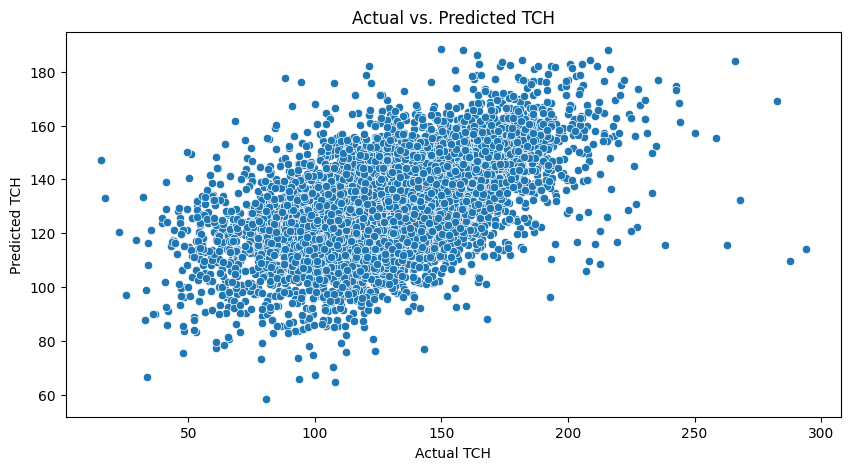

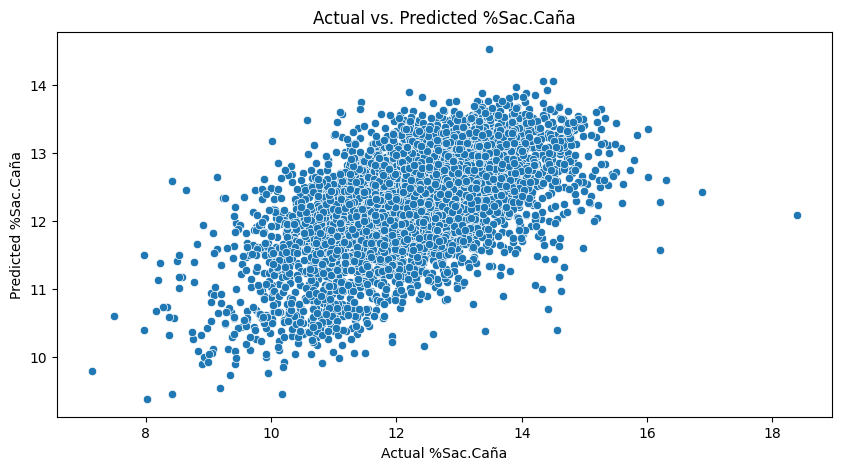

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot para modelo TCH
plt.figure(figsize=(10, 5))
sns.scatterplot(x=Y_te['TCH'], y=pred_TCH)
plt.xlabel("Actual TCH")
plt.ylabel("Predicted TCH")
plt.title("Actual vs. Predicted TCH")
plt.show()

# Plot para modelo %Sac.Caña
plt.figure(figsize=(10, 5))
sns.scatterplot(x=Y_te['%Sac.Caña'], y=pred_SAC)
plt.xlabel("Actual %Sac.Caña")
plt.ylabel("Predicted %Sac.Caña")
plt.title("Actual vs. Predicted %Sac.Caña")
plt.show()

Las gráficas anteriores son una guía para validar si el supuesto de linealidad se está cumpliendo. Refiriendonos a las imagenes se observa que existe una relación ascendente pero no podríamos afirmar que es lineal, esto debido a que existe una alta dispersión de los datos; podríamos concluir que el modelo no cumple en su totalidad con una regresión lineal,  

### **16.2. Linealidad / Homoscedasticidad**

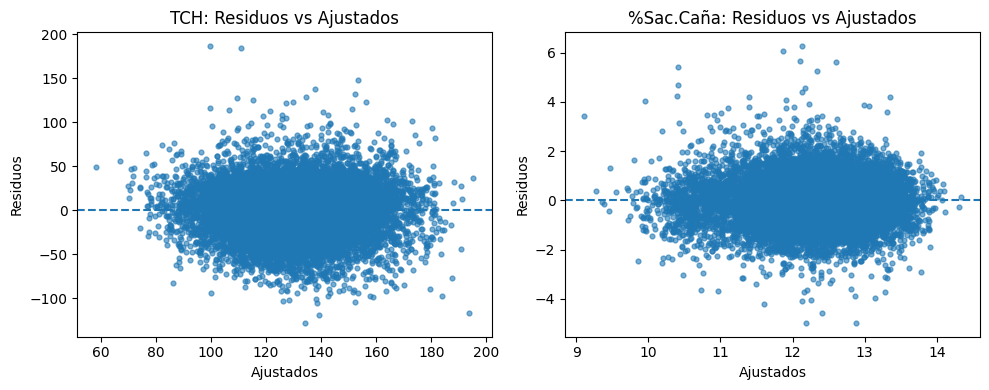

In [51]:
# TCH
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.scatter(ols_TCH.fittedvalues, ols_TCH.resid, s=12, alpha=0.6)
plt.axhline(0, ls="--")
plt.title("TCH: Residuos vs Ajustados")
plt.xlabel("Ajustados"); plt.ylabel("Residuos")

# %Sac.Caña
plt.subplot(1,2,2)
plt.scatter(ols_SAC.fittedvalues, ols_SAC.resid, s=12, alpha=0.6)
plt.axhline(0, ls="--")
plt.title("%Sac.Caña: Residuos vs Ajustados")
plt.xlabel("Ajustados"); plt.ylabel("Residuos")

plt.tight_layout(); plt.show()


- La gráfica de Residuos vs ajustados nos permite de manera práctica validar dos supuestos **Linealidad** y **Homocedasticidad**. Se observa en las gráficas un cumplimiento razonable de ambos supuestos, sin embargo, se realiza prueba de Bresuch-Pagan para caso de Homocedasticidad

#### **Breusch–Pagan**

La **homoscedasticidad** implica que la varianza de los errores es constante a lo largo de los valores de las variables independientes. Para evaluar este supuesto, se puede realizar la prueba de Breusch-Pagan: Prueba la hipótesis:

**H0** : *La varianza de los errores es constante (homoscedasticidad).*

**H1** : *La varianza de los errores no es constante (heteroscedasticidad).*

In [52]:

# TCH
bp_tch = het_breuschpagan(ols_TCH.resid, ols_TCH.model.exog)
print(f"BP TCH: p(LM)={bp_tch[1]:.4f}  p(F)={bp_tch[3]:.4f}")

# %Sac.Caña
bp_sac = het_breuschpagan(ols_SAC.resid, ols_SAC.model.exog)
print(f"BP %Sac: p(LM)={bp_sac[1]:.4f}  p(F)={bp_sac[3]:.4f}")

BP TCH: p(LM)=0.0000  p(F)=0.0000
BP %Sac: p(LM)=0.0000  p(F)=0.0000


**Se rechaza H0** porque el valor p para ambos modelos es inferior a 0,05 por lo que **la varianza de los errores no es constante** (heterocedasticidad). Cuando existe Heteroscedasticidad el modelo, los estimadores y los análisis de valor p pueden ser erroneos; por lo que se puede corregir esto utilizando WLS.

#### **16.3. Normalidad de los errores**

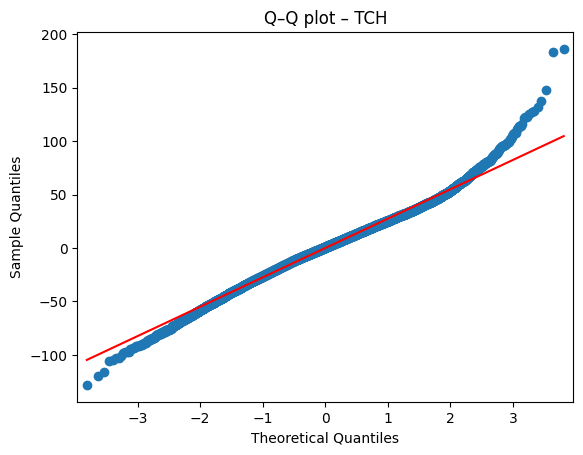

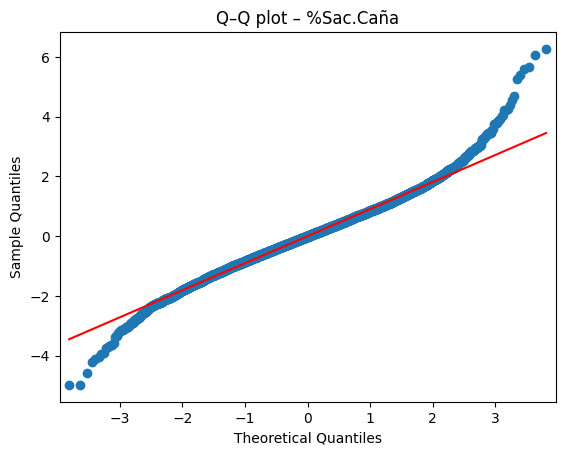

In [53]:
# QQ-plots

results_sm_tch = ols_TCH          
results_sm_sac_cana = ols_SAC     

sm.qqplot(results_sm_tch.resid, line='s'); plt.title("Q–Q plot – TCH"); plt.show()
sm.qqplot(results_sm_sac_cana.resid, line='s'); plt.title("Q–Q plot – %Sac.Caña"); plt.show()


En el gráfico de Q-Q se observa que la **mayoria** de puntos está sobre la línea roja, pero se observan unos puntos en la cola, que generan un curva ligera; dado este rsultado se decidió generar grafico de distribución, y hacer una prueba estadística.

#### **Distribución de los errores**

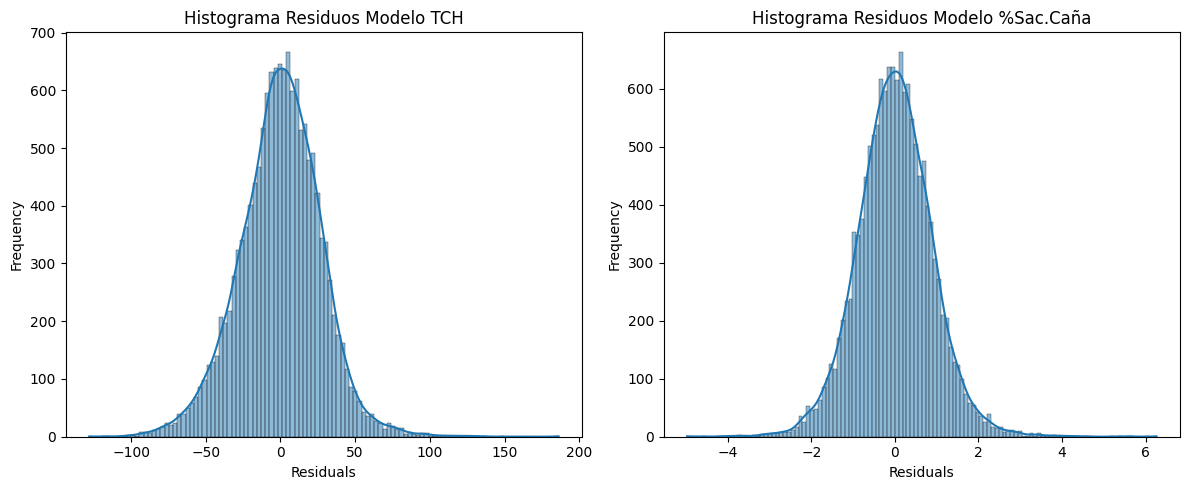

In [54]:
# Histogramas

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(results_sm_tch.resid, kde=True)
plt.title("Histograma Residuos Modelo TCH")
plt.xlabel("Residuals")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
sns.histplot(results_sm_sac_cana.resid, kde=True)
plt.title("Histograma Residuos Modelo %Sac.Caña")
plt.xlabel("Residuals")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


#### **Shapiro-Wilk**

**H0:** *establece que los datos siguen una distribución normal.*

**H1:** *establece que los datos no siguen una distribución normal.*

Interpretación: Si el p-valor es mayor que 0.05, no se rechaza H0 , lo que sugiere que los datos podrían seguir una distribución normal. 
Si el p-valor es menor que 0.05, se rechaza H0 , lo que indica que los datos probablemente no siguen una distribución normal.

In [55]:
# Shapiro-Wilk test para revisar normalidad
shapiro_test_tch = shapiro(results_sm_tch.resid)
print(f"Shapiro-Wilk test for TCH model residuals: Statistic={shapiro_test_tch.statistic:.4f}, p-value={shapiro_test_tch.pvalue:.4f}")

shapiro_test_sac_cana = shapiro(results_sm_sac_cana.resid)
print(f"Shapiro-Wilk test for %Sac.Caña model residuals: Statistic={shapiro_test_sac_cana.statistic:.4f}, p-value={shapiro_test_sac_cana.pvalue:.4f}")

Shapiro-Wilk test for TCH model residuals: Statistic=0.9916, p-value=0.0000
Shapiro-Wilk test for %Sac.Caña model residuals: Statistic=0.9884, p-value=0.0000


c:\Users\1116282909\AppData\Local\Programs\Python\Python313\Lib\site-packages\scipy\stats\_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 14403.
  res = hypotest_fun_out(*samples, **kwds)


Se realiza la prueba de Shapiro Wilk, y se **rechaza H0** por ende no podemos decir que la distribución es normal. A simple vista la observamos normal, sin embargo, al trabajar con una base de datos tan extensa, es normal que se rechace H0 a pesar de ver unas graficas con una distribución muy cercana a la normal


#### **16.4. Pairplots: top-K correlacionadas con el objetivo**

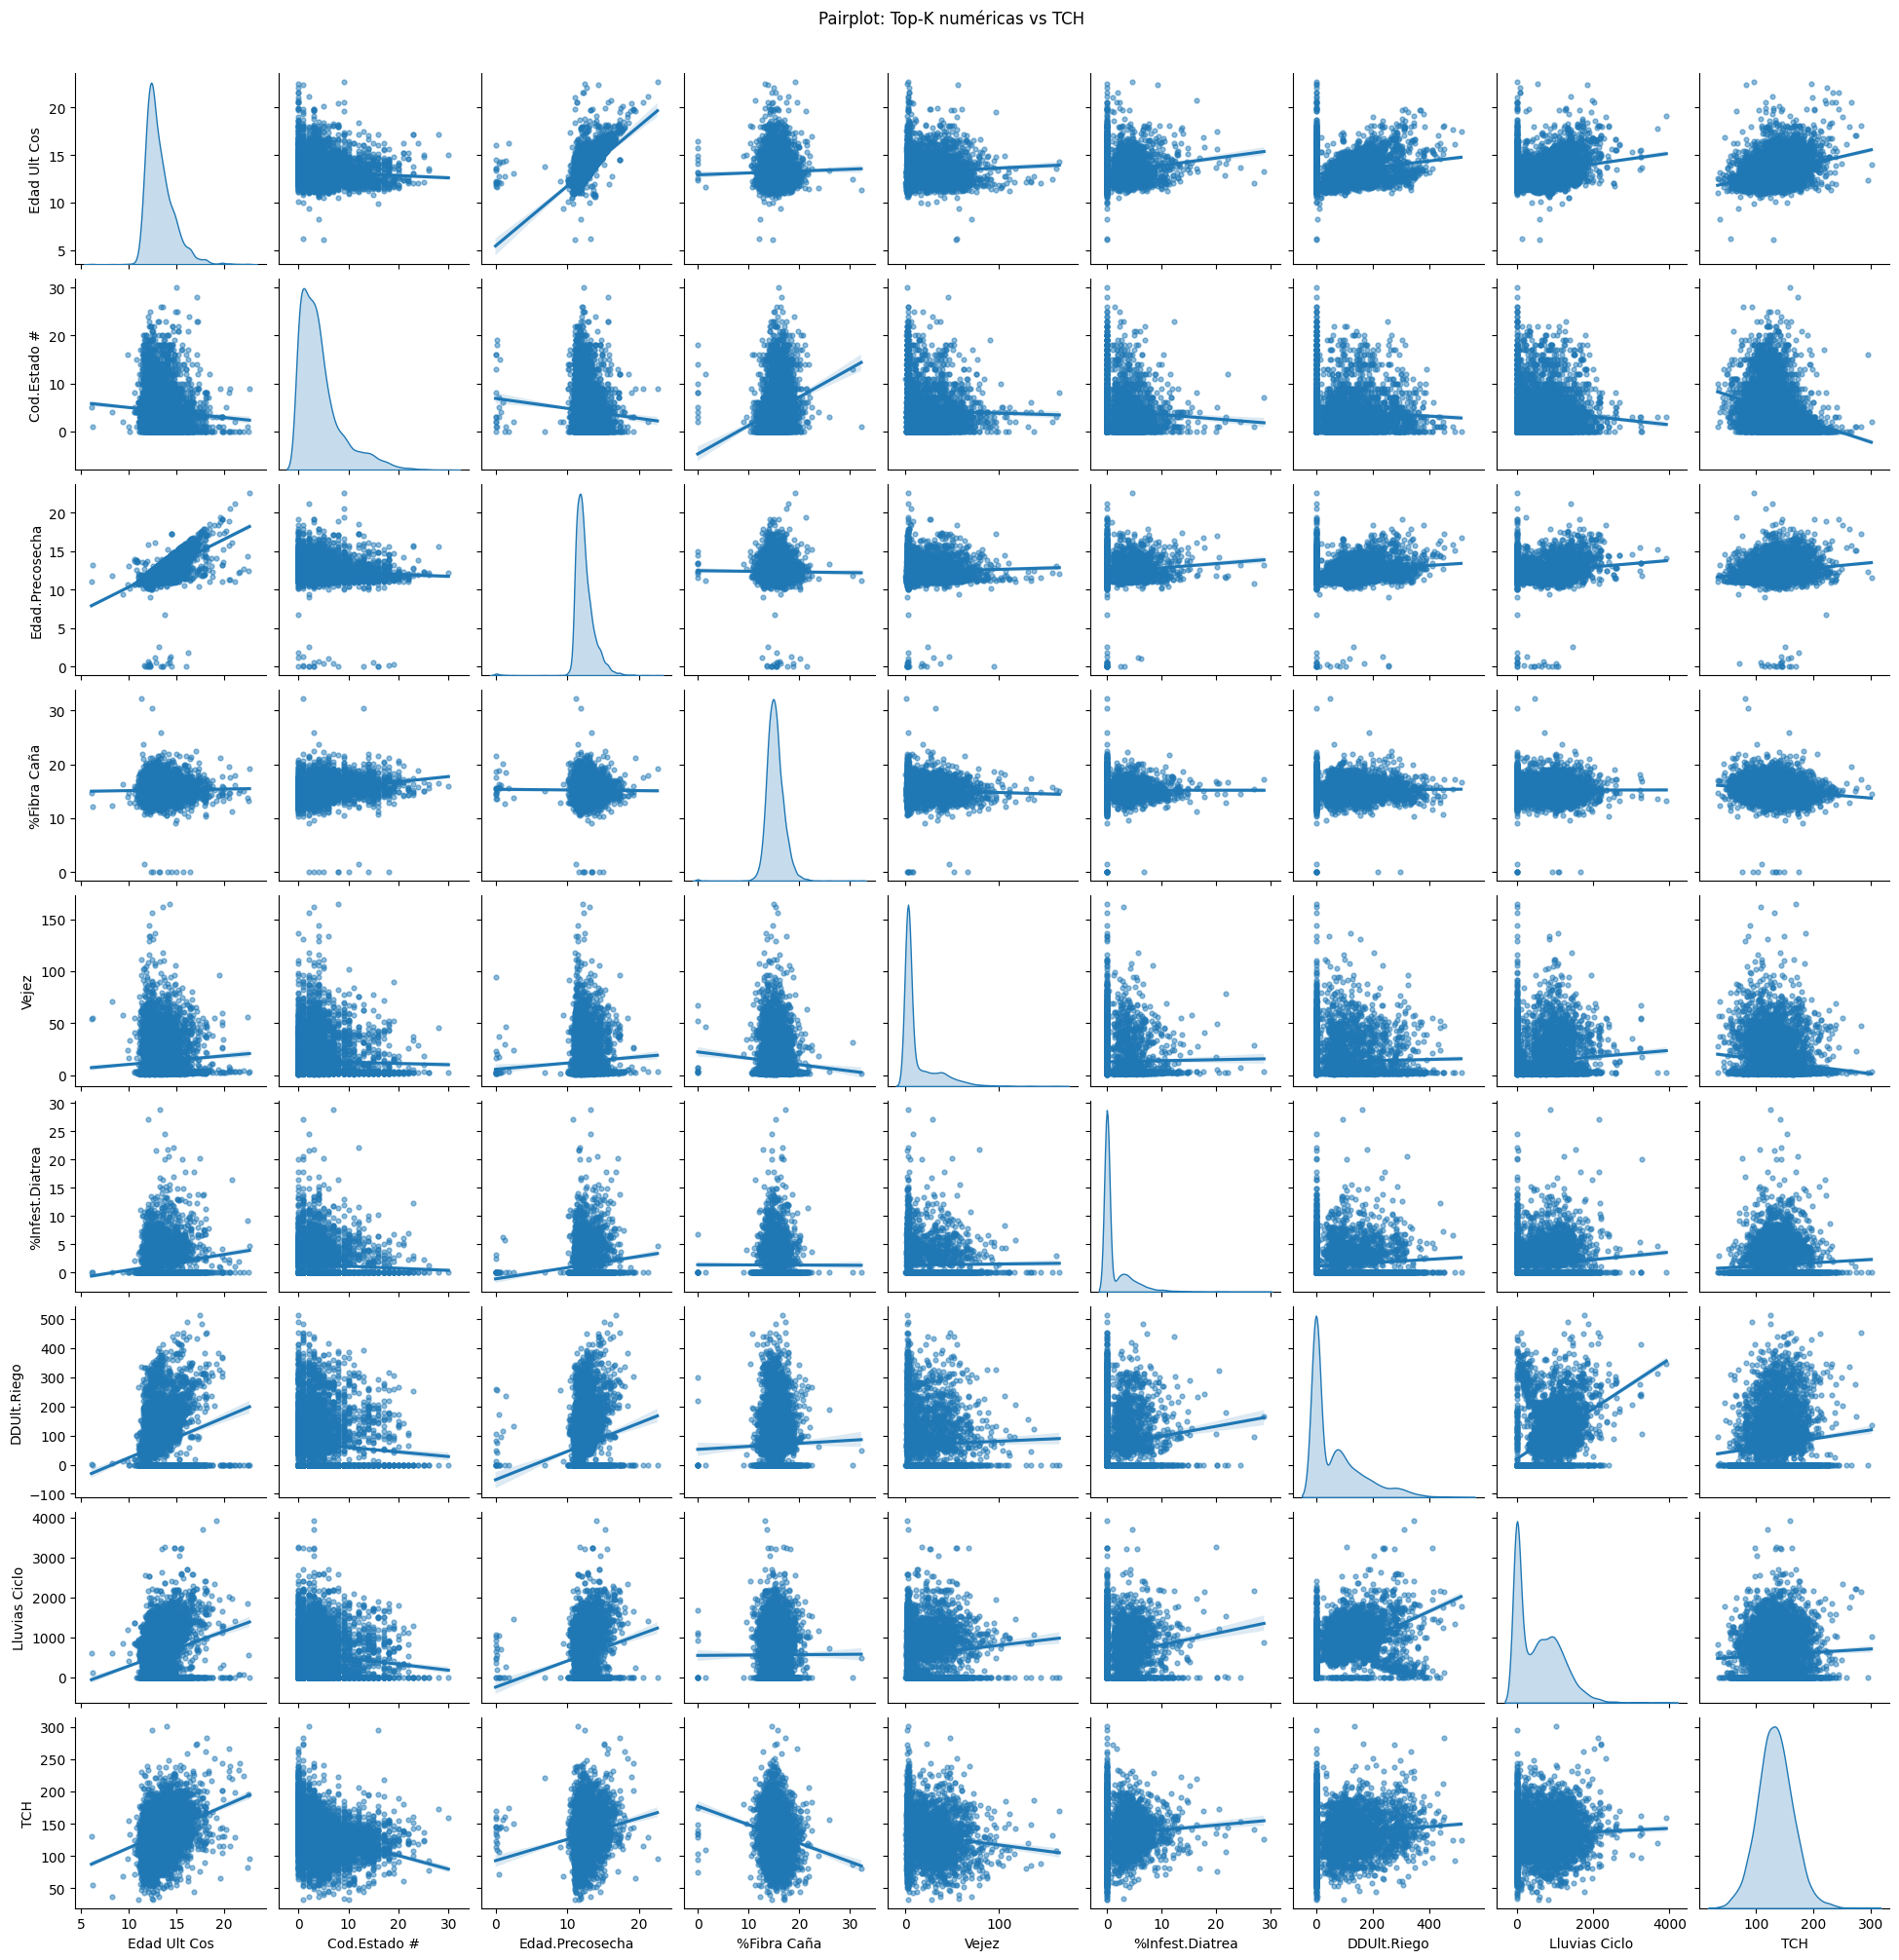

In [56]:
# Top-K con TCH

df_all = pd.concat([X_tr2, Y_tr['TCH']], axis=1)
num_cols = df_all.select_dtypes(include=[np.number, "Int64", "Float64"]).columns.tolist()
K = 8
corr_with_y = df_all[num_cols].corrwith(df_all['TCH']).abs().sort_values(ascending=False)
corr_with_y = corr_with_y.drop(labels=['TCH'], errors='ignore')
topk = corr_with_y.head(K).index.tolist()

plot_df = df_all[topk + ['TCH']].dropna()
g = sns.pairplot(plot_df, diag_kind="kde", kind="reg",
                 height=2.2, plot_kws={"scatter_kws": {"s": 12, "alpha": 0.5}})
g.fig.suptitle("Pairplot: Top-K numéricas vs TCH", y=1.02)
plt.show()


C:\Users\1116282909\AppData\Local\Temp\ipykernel_25744\996037561.py:45: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(xmin, xmax)


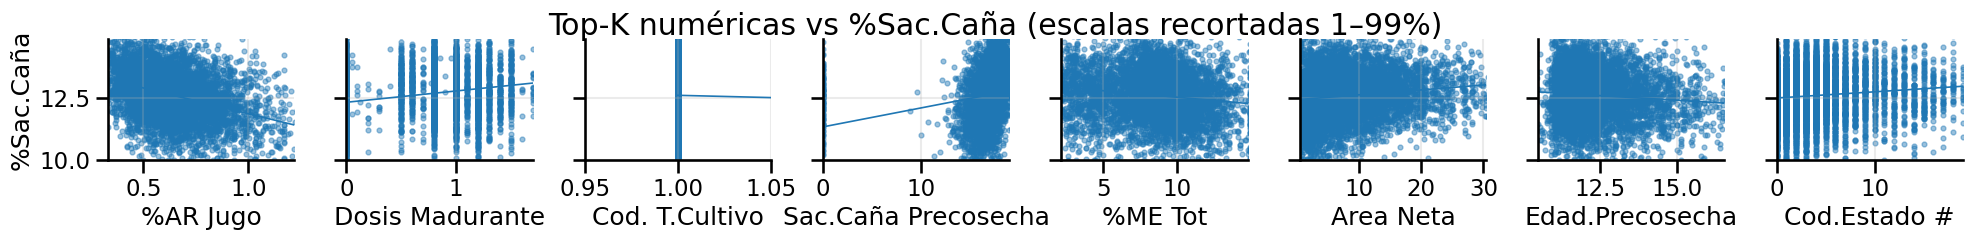

In [57]:
# Top-K con %Sac.Caña

ycol = "%Sac.Caña"
df_all = pd.concat([X_tr2, Y_tr[[ycol]]], axis=1)

num_cols = df_all.select_dtypes(include=[np.number, "Int64", "Float64"]).columns.tolist()
if ycol in num_cols:
    num_cols.remove(ycol)

K = 8
corrs = df_all[num_cols].corrwith(df_all[ycol]).abs().sort_values(ascending=False)
topk = corrs.head(K).index.tolist()

# Recorte robusto por cuantiles (1–99%) en Y y en cada X
plot_df = df_all[topk + [ycol]].dropna().copy()

# rango Y
ymin, ymax = plot_df[ycol].quantile([0.01, 0.99])

# rangos X por columna
xlims = {
    x: plot_df[x].quantile([0.01, 0.99]).to_list()  # [xmin, xmax]
    for x in topk
}

#Pairplot en una sola fila (y_vars) con límites por eje
sns.set_context("talk")
g = sns.pairplot(
    plot_df, y_vars=[ycol], x_vars=topk,
    kind="reg", diag_kind=None,
    height=2.4, aspect=1.05,
    plot_kws={
        "scatter_kws": {"s": 12, "alpha": 0.45},
        "line_kws": {"linewidth": 1.2},
        "ci": None
    }
)

# aplica límites y formato a cada subplot
for ax, x in zip(g.axes[0], topk):
    # Y común
    ax.set_ylim(ymin, ymax)
    # X por variable
    xmin, xmax = xlims[x]
    ax.set_xlim(xmin, xmax)
    # sin notación científica ni offsets
    ax.ticklabel_format(style='plain', useOffset=False, axis='both')
    ax.xaxis.get_offset_text().set_visible(False)
    ax.yaxis.get_offset_text().set_visible(False)
    # grid suave
    ax.grid(True, alpha=0.25)

g.fig.subplots_adjust(wspace=0.28, top=0.86, left=0.06, right=0.98)
g.fig.suptitle("Top-K numéricas vs %Sac.Caña (escalas recortadas 1–99%)")
plt.show()


### **17. Conclusiones**

##### **Variables determinantes en TCH**

**↑ Aumentan TCH:**

- Edad última cosecha (coef. +12 aprox.)
- Zona geográfica (IP02, IP03, IP05, IP06)
- Riego (m³/ha) y lluvias moderadas
- Sac. caña precosecha (indicador de madurez positiva).

**↓ Reducen TCH:**

- Semanas de maduración excesivas, % fibra y distancia Km (efectos negativos y consistentes).
- Algunas variedades (RB73-2223, CC93-4418, CC85-92) con betas negativas estables.
- Cod. Estado # refleja pérdidas operativas significativas.

##### **Variables determinantes en %Sac.Caña**

**↑ Aumentan %Sac:**

- Madurez (semanas y precosecha).
- Prácticas de quema verde.
- Uso de ciertos madurantes (TRONNUSPAC, BONUS 250).
- Variedad CC93-4418 con efecto positivo.

**↓ Reducen %Sac:**

- %AR jugo (el predictor más fuerte, negativo y esperado).
- %ME total (más materia extraña reduce sacarosa).
- Corte mecanizado penaliza frente a manual/definido.
- Exceso de lluvias también diluye sacarosa.

##### **Evaluación de modelos**

- OLS: buen punto de partida, explicabilidad clara (R² = 0.286 TCH, 0.377 %Sac).
- LassoCV: muy similar a Ridge, útil para selección de variables.
- RidgeCV: mantiene todos los predictores (incluidas dummies críticas) y estabiliza coeficientes ante multicolinealidad alta → mejor opción práctica.

#### **Multicolinealidad**

- Muy alta en dummies de tipo de quema y productos (VIF > 40).
- En numéricas, VIF < 2.5 (sin problema).
- Las dummies tienden a inflar artificialmente el VIF, sobre todo en categorías poco frecuentes.

Decisión: usar Ridge → conserva todas las variables y reduce varianza en coeficientes sin eliminar niveles relevantes.

#### **Supuesto de linealidad**

Pairplots muestran relaciones poco lineales, vale la pena explorar otros modelos más complejos.

#### **Recomendaciones estratégicas**

- Gestión de variedades y zonal: ajustar plan de siembra hacia variedades y zonas con coeficientes positivos.
- Optimizar corte: balancear semanas de maduración y logística para maximizar ingreso neto (TCH × %Sac).
- Procesos: priorizar reducción de materia extraña y mejorar control de jugo (%AR).
- Insumos: validar efectos de madurantes con ensayos controlados.